# PROYECTO INTEGRADOR PARCIAL I
## Pipeline Completo de Minería de Datos

**Instituto Politécnico Nacional**  
**Unidad Profesional Interdisciplinaria de Ingeniería Campus Tlaxcala (UPIIT)**  
**Ingeniería en Inteligencia Artificial**

### Proyecto
**Predicción de la gravedad de accidentes de tránsito mediante técnicas de Minería de Datos**

### Metodología
CRISP-DM

### Tipo de problema
Clasificación binaria

### Variable objetivo
Gravedad del accidente: **Grave / No grave**

In [ ]:
# Manipulación de datos
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# División y validación
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate

# Preprocesamiento
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Modelos
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Evaluación
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [ ]:
# Semilla para reproducibilidad
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Mostrar todas las columnas
pd.set_option("display.max_columns", None)

# Configuración de gráficas
sns.set_theme(style="whitegrid")

print("Configuración completada.")
print("Semilla:", RANDOM_STATE)

Configuración completada.
Semilla: 42


In [ ]:
!pip install -q kagglehub

In [ ]:
import kagglehub

# Descarga de el dataset directamente desde Kaggle
path = kagglehub.dataset_download("sobhanmoosavi/us-accidents")

print("Dataset descargado en:")
print(path)

Using Colab cache for faster access to the 'us-accidents' dataset.
Dataset descargado en:
/kaggle/input/us-accidents


In [ ]:
ruta = os.path.join(path, "US_Accidents_March23.csv")

columnas = [
    "Severity",
    "Start_Time",
    "Distance(mi)",
    "City",
    "State",
    "Temperature(F)",
    "Humidity(%)",
    "Pressure(in)",
    "Visibility(mi)",
    "Wind_Speed(mph)",
    "Precipitation(in)",
    "Weather_Condition",
    "Amenity",
    "Crossing",
    "Junction",
    "Railway",
    "Station",
    "Stop",
    "Traffic_Signal",
    "Sunrise_Sunset"
]

df = pd.read_csv(
    ruta,
    usecols=columnas
)

print("Dataset cargado correctamente")
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

display(df.head())

Dataset cargado correctamente
Filas: 7728394
Columnas: 20


,Severity,Start_Time,Distance(mi),City,State,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Weather_Condition,Amenity,Crossing,Junction,Railway,Station,Stop,Traffic_Signal,Sunrise_Sunset
0,3,2016-02-08 05:46:00,0.01,Dayton,OH,36.9,91.0,29.68,10.0,NaN,0.02,Light Rain,False,False,False,False,False,False,False,Night
1,2,2016-02-08 06:07:59,0.01,Reynoldsburg,OH,37.9,100.0,29.65,10.0,NaN,0.00,Light Rain,False,False,False,False,False,False,False,Night
2,2,2016-02-08 06:49:27,0.01,Williamsburg,OH,36.0,100.0,29.67,10.0,3.5,NaN,Overcast,False,False,False,False,False,False,True,Night
3,3,2016-02-08 07:23:34,0.01,Dayton,OH,35.1,96.0,29.64,9.0,4.6,NaN,Mostly Cloudy,False,False,False,False,False,False,False,Night
4,2,2016-02-08 07:39:07,0.01,Dayton,OH,36.0,89.0,29.65,6.0,3.5,NaN,Mostly Cloudy,False,False,False,False,False,False,True,Day


In [ ]:
# Crear una muestra reproducible de 50,000 accidentes

df_muestra = df.sample(
    n=50000,
    random_state=42
).reset_index(drop=True)

print("Dataset de trabajo creado correctamente.")
print("Filas:", df_muestra.shape[0])
print("Columnas:", df_muestra.shape[1])

display(df_muestra.head())

Dataset de trabajo creado correctamente.
Filas: 50000
Columnas: 20


,Severity,Start_Time,Distance(mi),City,State,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Weather_Condition,Amenity,Crossing,Junction,Railway,Station,Stop,Traffic_Signal,Sunrise_Sunset
0,1,2020-04-17 09:29:30,0.000,West Palm Beach,FL,78.0,81.0,30.13,10.0,13.0,0.01,Mostly Cloudy,False,False,False,False,False,False,True,Day
1,2,2022-04-21 10:01:00.000000000,0.045,Roseville,CA,55.0,88.0,29.83,10.0,9.0,0.00,Mostly Cloudy,False,True,False,False,False,True,False,Day
2,3,2016-08-12 16:45:00,0.000,Alpharetta,GA,91.0,47.0,29.91,10.0,10.4,NaN,Partly Cloudy,False,True,False,False,False,False,False,Day
3,3,2019-09-20 15:22:16,0.000,Tacoma,WA,67.0,84.0,29.78,10.0,3.0,0.00,Cloudy,False,False,False,False,False,False,False,Day
4,2,2019-06-03 16:55:43,0.000,Scottsdale,AZ,95.0,16.0,28.53,10.0,6.0,0.00,Fair,False,False,False,False,False,False,False,Day


In [ ]:
# Liberar el dataset completo de la memoria

del df

import gc
gc.collect()

print("Memoria liberada.")

Memoria liberada.


In [ ]:
# Información general del dataset

print("INFORMACIÓN GENERAL DEL DATASET")


print("\nDimensiones:")
print("Filas:", df_muestra.shape[0])
print("Columnas:", df_muestra.shape[1])

print("\nNombres de las variables:")
for i, columna in enumerate(df_muestra.columns, start=1):
    print(f"{i}. {columna}")

print("\nTipos de datos:")
print(df_muestra.dtypes)

INFORMACIÓN GENERAL DEL DATASET

Dimensiones:
Filas: 50000
Columnas: 20

Nombres de las variables:
1. Severity
2. Start_Time
3. Distance(mi)
4. City
5. State
6. Temperature(F)
7. Humidity(%)
8. Pressure(in)
9. Visibility(mi)
10. Wind_Speed(mph)
11. Precipitation(in)
12. Weather_Condition
13. Amenity
14. Crossing
15. Junction
16. Railway
17. Station
18. Stop
19. Traffic_Signal
20. Sunrise_Sunset

Tipos de datos:
Severity               int64
Start_Time            object
Distance(mi)         float64
City                  object
State                 object
Temperature(F)       float64
Humidity(%)          float64
Pressure(in)         float64
Visibility(mi)       float64
Wind_Speed(mph)      float64
Precipitation(in)    float64
Weather_Condition     object
Amenity                 bool
Crossing                bool
Junction                bool
Railway                 bool
Station                 bool
Stop                    bool
Traffic_Signal          bool
Sunrise_Sunset        object
dtype

In [ ]:
# Auditoría de valores nulos

nulos = df_muestra.isnull().sum()
porcentaje_nulos = (nulos / len(df_muestra)) * 100

tabla_nulos = pd.DataFrame({
    "Valores_Nulos": nulos,
    "Porcentaje": porcentaje_nulos.round(2)
})

tabla_nulos = tabla_nulos.sort_values(
    by="Porcentaje",
    ascending=False
)

print("=" * 50)
print("AUDITORÍA DE VALORES NULOS")
print("=" * 50)

display(tabla_nulos)

AUDITORÍA DE VALORES NULOS


,Valores_Nulos,Porcentaje
Precipitation(in),14375,28.75
Wind_Speed(mph),3811,7.62
Visibility(mi),1136,2.27
Humidity(%),1126,2.25
Weather_Condition,1108,2.22
Temperature(F),1061,2.12
Pressure(in),905,1.81
Sunrise_Sunset,165,0.33
City,0,0.00
Distance(mi),0,0.00


In [ ]:
# Auditoría de registros duplicados

duplicados = df_muestra.duplicated().sum()
porcentaje_duplicados = (duplicados / len(df_muestra)) * 100

print("AUDITORÍA DE DUPLICADOS")

print("Registros totales:", len(df_muestra))
print("Registros duplicados:", duplicados)
print(f"Porcentaje de duplicados: {porcentaje_duplicados:.2f}%")

AUDITORÍA DE DUPLICADOS
Registros totales: 50000
Registros duplicados: 21
Porcentaje de duplicados: 0.04%


In [ ]:
# Distribución de la variable objetivo original

conteo_severity = df_muestra["Severity"].value_counts().sort_index()
porcentaje_severity = (
    df_muestra["Severity"].value_counts(normalize=True)
    .sort_index() * 100
)

tabla_severity = pd.DataFrame({
    "Cantidad": conteo_severity,
    "Porcentaje": porcentaje_severity.round(2)
})


print("DISTRIBUCIÓN DE SEVERITY")


display(tabla_severity)

DISTRIBUCIÓN DE SEVERITY


,Cantidad,Porcentaje
Severity,,
1,425,0.85
2,39858,79.72
3,8418,16.84
4,1299,2.60


In [ ]:
# Crear variable objetivo binaria
# 0 = No grave (Severity 1 y 2)
# 1 = Grave    (Severity 3 y 4)

df_muestra["Grave"] = (df_muestra["Severity"] >= 3).astype(int)

conteo = df_muestra["Grave"].value_counts().sort_index()
porcentaje = (
    df_muestra["Grave"].value_counts(normalize=True)
    .sort_index() * 100
)

tabla_gravedad = pd.DataFrame({
    "Cantidad": conteo,
    "Porcentaje": porcentaje.round(2)
})

tabla_gravedad.index = ["No grave (0)", "Grave (1)"]

print("DISTRIBUCIÓN DE LA VARIABLE OBJETIVO")
display(tabla_gravedad)

DISTRIBUCIÓN DE LA VARIABLE OBJETIVO


,Cantidad,Porcentaje
No grave (0),40283,80.57
Grave (1),9717,19.43


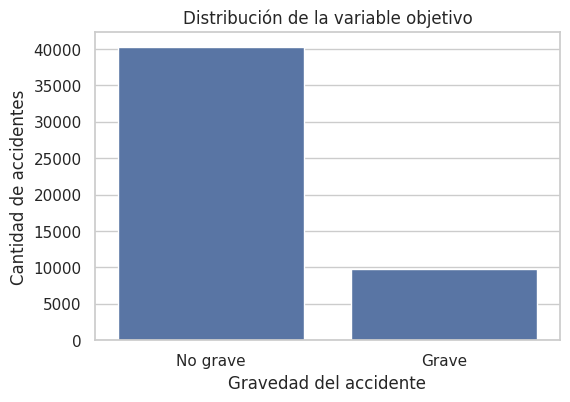

In [ ]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df_muestra,
    x="Grave"
)

plt.title("Distribución de la variable objetivo")
plt.xlabel("Gravedad del accidente")
plt.ylabel("Cantidad de accidentes")
plt.xticks([0, 1], ["No grave", "Grave"])

plt.show()

In [ ]:
# Convertir fecha a formato datetime
df_muestra["Start_Time"] = pd.to_datetime(
    df_muestra["Start_Time"],
    errors="coerce"
)

# Extraer características de la fecha
df_muestra["Hora"] = df_muestra["Start_Time"].dt.hour
df_muestra["Mes"] = df_muestra["Start_Time"].dt.month
df_muestra["Dia_Semana"] = df_muestra["Start_Time"].dt.dayofweek

# Variables predictoras
X = df_muestra.drop(
    columns=["Severity", "Grave", "Start_Time"]
)

# Variable objetivo
y = df_muestra["Grave"]

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

display(X.head())

Dimensiones de X: (50000, 21)
Dimensiones de y: (50000,)


,Distance(mi),City,State,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Weather_Condition,Amenity,Crossing,Junction,Railway,Station,Stop,Traffic_Signal,Sunrise_Sunset,Hora,Mes,Dia_Semana
0,0.000,West Palm Beach,FL,78.0,81.0,30.13,10.0,13.0,0.01,Mostly Cloudy,False,False,False,False,False,False,True,Day,9.0,4.0,4.0
1,0.045,Roseville,CA,55.0,88.0,29.83,10.0,9.0,0.00,Mostly Cloudy,False,True,False,False,False,True,False,Day,NaN,NaN,NaN
2,0.000,Alpharetta,GA,91.0,47.0,29.91,10.0,10.4,NaN,Partly Cloudy,False,True,False,False,False,False,False,Day,16.0,8.0,4.0
3,0.000,Tacoma,WA,67.0,84.0,29.78,10.0,3.0,0.00,Cloudy,False,False,False,False,False,False,False,Day,15.0,9.0,4.0
4,0.000,Scottsdale,AZ,95.0,16.0,28.53,10.0,6.0,0.00,Fair,False,False,False,False,False,False,False,Day,16.0,6.0,0.0


In [ ]:
# Partición hermética Train/Test

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Tamaño del conjunto de entrenamiento:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTamaño del conjunto de prueba:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Tamaño del conjunto de entrenamiento:
X_train: (40000, 21)
y_train: (40000,)

Tamaño del conjunto de prueba:
X_test: (10000, 21)
y_test: (10000,)


In [ ]:
# Verificar que se conservó la distribución de clases

print("Distribución TOTAL:")
print((y.value_counts(normalize=True) * 100).round(2))

print("\nDistribución TRAIN:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nDistribución TEST:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Distribución TOTAL:
Grave
0    80.57
1    19.43
Name: proportion, dtype: float64

Distribución TRAIN:
Grave
0    80.56
1    19.43
Name: proportion, dtype: float64

Distribución TEST:
Grave
0    80.57
1    19.43
Name: proportion, dtype: float64


In [ ]:
# Identificar tipos de variables

columnas_numericas = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

columnas_categoricas = X_train.select_dtypes(
    include=["object", "bool"]
).columns.tolist()

print("VARIABLES NUMÉRICAS:")
print(columnas_numericas)

print("\nVARIABLES CATEGÓRICAS:")
print(columnas_categoricas)

print("\nCantidad numéricas:", len(columnas_numericas))
print("Cantidad categóricas:", len(columnas_categoricas))

VARIABLES NUMÉRICAS:
['Distance(mi)', 'Temperature(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)', 'Hora', 'Mes', 'Dia_Semana']

VARIABLES CATEGÓRICAS:
['City', 'State', 'Weather_Condition', 'Amenity', 'Crossing', 'Junction', 'Railway', 'Station', 'Stop', 'Traffic_Signal', 'Sunrise_Sunset']

Cantidad numéricas: 10
Cantidad categóricas: 11


In [ ]:
# Pipeline para variables numéricas
pipeline_numerico = Pipeline(steps=[
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler())
])

# Pipeline para variables categóricas
pipeline_categorico = Pipeline(steps=[
    ("imputacion", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

print("Pipelines creados correctamente.")

Pipelines creados correctamente.


In [ ]:
# ColumnTransformer para aplicar diferentes transformaciones
# según el tipo de variable

preprocesador = ColumnTransformer(
    transformers=[
        ("numericas", pipeline_numerico, columnas_numericas),
        ("categoricas", pipeline_categorico, columnas_categoricas)
    ]
)

print("ColumnTransformer creado correctamente.")

ColumnTransformer creado correctamente.


In [ ]:
# Pipeline completo:
# Preprocesamiento + Regresión Logística

modelo_logistico = Pipeline(steps=[
    ("preprocesamiento", preprocesador),

    ("modelo", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

print("Pipeline completo de Regresión Logística creado.")

Pipeline completo de Regresión Logística creado.


In [ ]:
# Entrenar únicamente con TRAIN

modelo_logistico.fit(X_train, y_train)

print("Modelo entrenado correctamente.")

Modelo entrenado correctamente.


In [ ]:
# Predicciones sobre el conjunto de prueba

y_pred_log = modelo_logistico.predict(X_test)

# Probabilidades de pertenecer a la clase Grave
y_prob_log = modelo_logistico.predict_proba(X_test)[:, 1]

print("Predicciones realizadas correctamente.")
print("Cantidad de predicciones:", len(y_pred_log))

Predicciones realizadas correctamente.
Cantidad de predicciones: 10000


In [ ]:
# Evaluación de la Regresión Logística

accuracy_log = accuracy_score(y_test, y_pred_log)
precision_log = precision_score(y_test, y_pred_log)
recall_log = recall_score(y_test, y_pred_log)
f1_log = f1_score(y_test, y_pred_log)
roc_auc_log = roc_auc_score(y_test, y_prob_log)


print("RESULTADOS - REGRESIÓN LOGÍSTICA")

print(f"Accuracy : {accuracy_log:.4f}")
print(f"Precision: {precision_log:.4f}")
print(f"Recall   : {recall_log:.4f}")
print(f"F1-Score : {f1_log:.4f}")
print(f"ROC-AUC  : {roc_auc_log:.4f}")

RESULTADOS - REGRESIÓN LOGÍSTICA
Accuracy : 0.7094
Precision: 0.3679
Recall   : 0.6902
F1-Score : 0.4800
ROC-AUC  : 0.7701


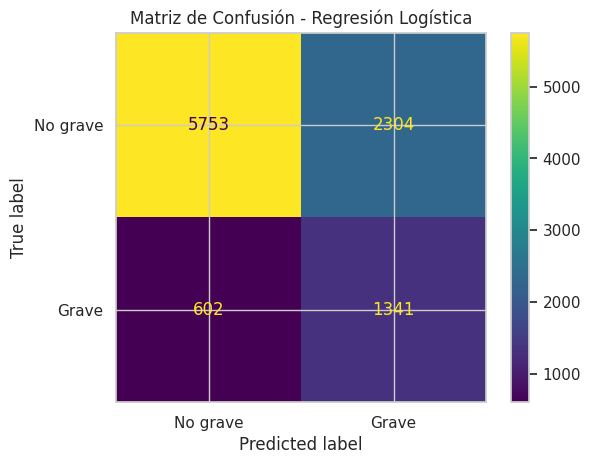

In [ ]:
# Matriz de confusión

cm_log = confusion_matrix(y_test, y_pred_log)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_log,
    display_labels=["No grave", "Grave"]
)

disp.plot()
plt.title("Matriz de Confusión - Regresión Logística")
plt.show()

In [ ]:
print(
    classification_report(
        y_test,
        y_pred_log,
        target_names=["No grave", "Grave"]
    )
)

              precision    recall  f1-score   support

    No grave       0.91      0.71      0.80      8057
       Grave       0.37      0.69      0.48      1943

    accuracy                           0.71     10000
   macro avg       0.64      0.70      0.64     10000
weighted avg       0.80      0.71      0.74     10000



In [ ]:
# Pipeline completo:
# Preprocesamiento + Random Forest

modelo_rf = Pipeline(steps=[
    ("preprocesamiento", preprocesador),

    ("modelo", RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_split=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

print("Pipeline de Random Forest creado correctamente.")

Pipeline de Random Forest creado correctamente.


In [ ]:
# Entrenar Random Forest únicamente con TRAIN

modelo_rf.fit(X_train, y_train)

print("Random Forest entrenado correctamente.")

Random Forest entrenado correctamente.


In [ ]:
# Predicciones

y_pred_rf = modelo_rf.predict(X_test)

# Probabilidad de que el accidente sea Grave
y_prob_rf = modelo_rf.predict_proba(X_test)[:, 1]

print("Predicciones realizadas:", len(y_pred_rf))

Predicciones realizadas: 10000


In [ ]:
# Métricas de evaluación

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)


print("RESULTADOS - RANDOM FOREST")


print(f"Accuracy : {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall   : {recall_rf:.4f}")
print(f"F1-Score : {f1_rf:.4f}")
print(f"ROC-AUC  : {roc_auc_rf:.4f}")

RESULTADOS - RANDOM FOREST
Accuracy : 0.7355
Precision: 0.4015
Recall   : 0.7360
F1-Score : 0.5195
ROC-AUC  : 0.7923


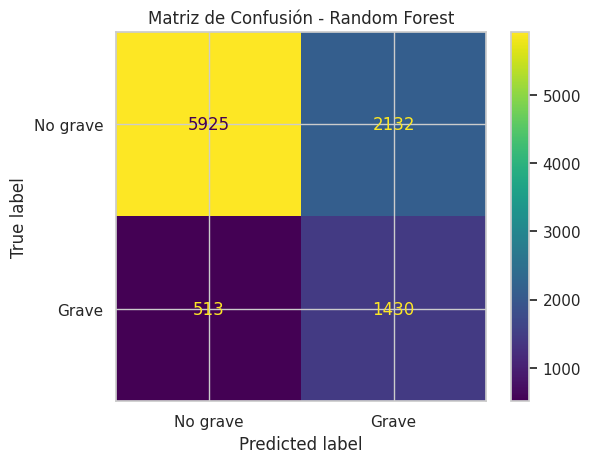

In [ ]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["No grave", "Grave"]
)

disp.plot()
plt.title("Matriz de Confusión - Random Forest")
plt.show()

In [ ]:
resultados = pd.DataFrame({
    "Modelo": [
        "Regresión Logística",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_log,
        accuracy_rf
    ],
    "Precision": [
        precision_log,
        precision_rf
    ],
    "Recall": [
        recall_log,
        recall_rf
    ],
    "F1-Score": [
        f1_log,
        f1_rf
    ],
    "ROC-AUC": [
        roc_auc_log,
        roc_auc_rf
    ]
})

resultados = resultados.round(4)

display(resultados)

,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Regresión Logística,0.7094,0.3679,0.6902,0.4800,0.7701
1,Random Forest,0.7355,0.4015,0.7360,0.5195,0.7923


In [ ]:
# Validación cruzada estratificada de 5 folds

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

metricas_cv = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

print("Validación cruzada configurada correctamente.")

Validación cruzada configurada correctamente.


In [ ]:
cv_log = cross_validate(
    modelo_logistico,
    X_train,
    y_train,
    cv=cv,
    scoring=metricas_cv,
    n_jobs=-1
)

print("Validación de Regresión Logística completada.")

Validación de Regresión Logística completada.


In [ ]:
cv_rf = cross_validate(
    modelo_rf,
    X_train,
    y_train,
    cv=cv,
    scoring=metricas_cv,
    n_jobs=-1
)

print("Validación de Random Forest completada.")

Validación de Random Forest completada.


In [ ]:
resultados_cv = pd.DataFrame({
    "Modelo": [
        "Regresión Logística",
        "Random Forest"
    ],

    "Accuracy promedio": [
        cv_log["test_accuracy"].mean(),
        cv_rf["test_accuracy"].mean()
    ],

    "Precision promedio": [
        cv_log["test_precision"].mean(),
        cv_rf["test_precision"].mean()
    ],

    "Recall promedio": [
        cv_log["test_recall"].mean(),
        cv_rf["test_recall"].mean()
    ],

    "F1 promedio": [
        cv_log["test_f1"].mean(),
        cv_rf["test_f1"].mean()
    ],

    "ROC-AUC promedio": [
        cv_log["test_roc_auc"].mean(),
        cv_rf["test_roc_auc"].mean()
    ],

    "F1 desviación": [
        cv_log["test_f1"].std(),
        cv_rf["test_f1"].std()
    ]
})

display(resultados_cv.round(4))

,Modelo,Accuracy promedio,Precision promedio,Recall promedio,F1 promedio,ROC-AUC promedio,F1 desviación
0,Regresión Logística,0.7087,0.3646,0.6717,0.4727,0.7659,0.0059
1,Random Forest,0.7411,0.4062,0.7189,0.5191,0.7933,0.0038


In [ ]:
# Estadísticas descriptivas de las variables numéricas

columnas_eda = [
    "Distance(mi)",
    "Temperature(F)",
    "Humidity(%)",
    "Pressure(in)",
    "Visibility(mi)",
    "Wind_Speed(mph)",
    "Precipitation(in)"
]

display(
    df_muestra[columnas_eda]
    .describe()
    .round(2)
)

,Distance(mi),Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in)
count,50000.00,48939.00,48874.00,49095.00,48864.00,46189.00,35625.00
mean,0.56,61.46,64.85,29.54,9.09,7.70,0.01
std,1.71,19.13,22.80,1.01,2.70,6.55,0.09
min,0.00,-35.00,3.00,16.72,0.00,0.00,0.00
25%,0.00,49.00,48.00,29.37,10.00,4.60,0.00
50%,0.03,64.00,67.00,29.86,10.00,7.00,0.00
75%,0.46,76.00,84.00,30.03,10.00,10.40,0.00
max,104.30,115.00,100.00,30.91,80.00,822.80,10.00


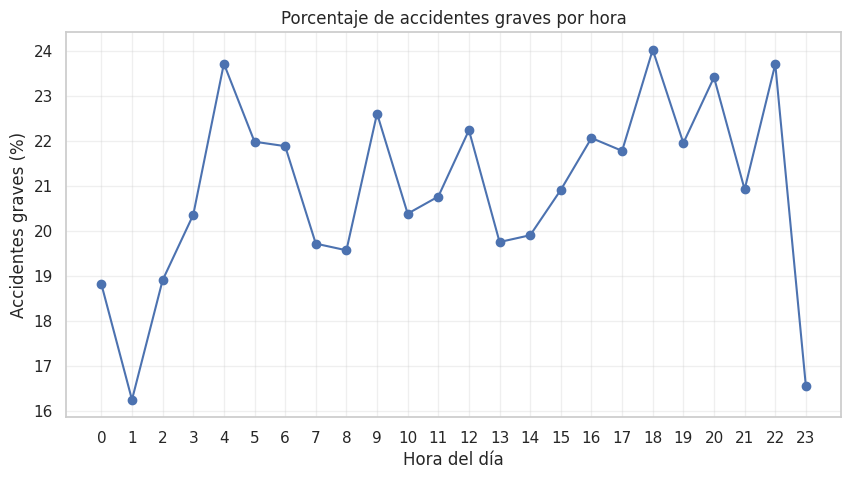

In [ ]:
# Porcentaje de accidentes graves por hora del día

gravedad_hora = (
    df_muestra
    .groupby("Hora")["Grave"]
    .mean() * 100
)

plt.figure(figsize=(10, 5))

plt.plot(
    gravedad_hora.index,
    gravedad_hora.values,
    marker="o"
)

plt.title("Porcentaje de accidentes graves por hora")
plt.xlabel("Hora del día")
plt.ylabel("Accidentes graves (%)")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)

plt.show()

In [ ]:
gravedad_sol = (
    df_muestra
    .groupby("Sunrise_Sunset")["Grave"]
    .agg(["count", "mean"])
)

gravedad_sol["Porcentaje_graves"] = (
    gravedad_sol["mean"] * 100
)

display(
    gravedad_sol[
        ["count", "Porcentaje_graves"]
    ].round(2)
)

,count,Porcentaje_graves
Sunrise_Sunset,,
Day,34417,19.74
Night,15418,18.82


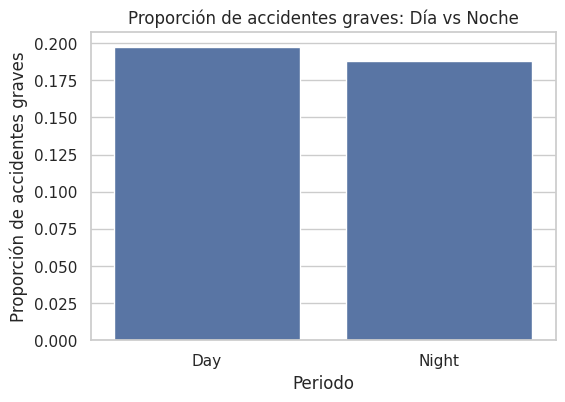

In [ ]:
plt.figure(figsize=(6, 4))

sns.barplot(
    data=df_muestra,
    x="Sunrise_Sunset",
    y="Grave",
    errorbar=None
)

plt.title("Proporción de accidentes graves: Día vs Noche")
plt.xlabel("Periodo")
plt.ylabel("Proporción de accidentes graves")

plt.show()

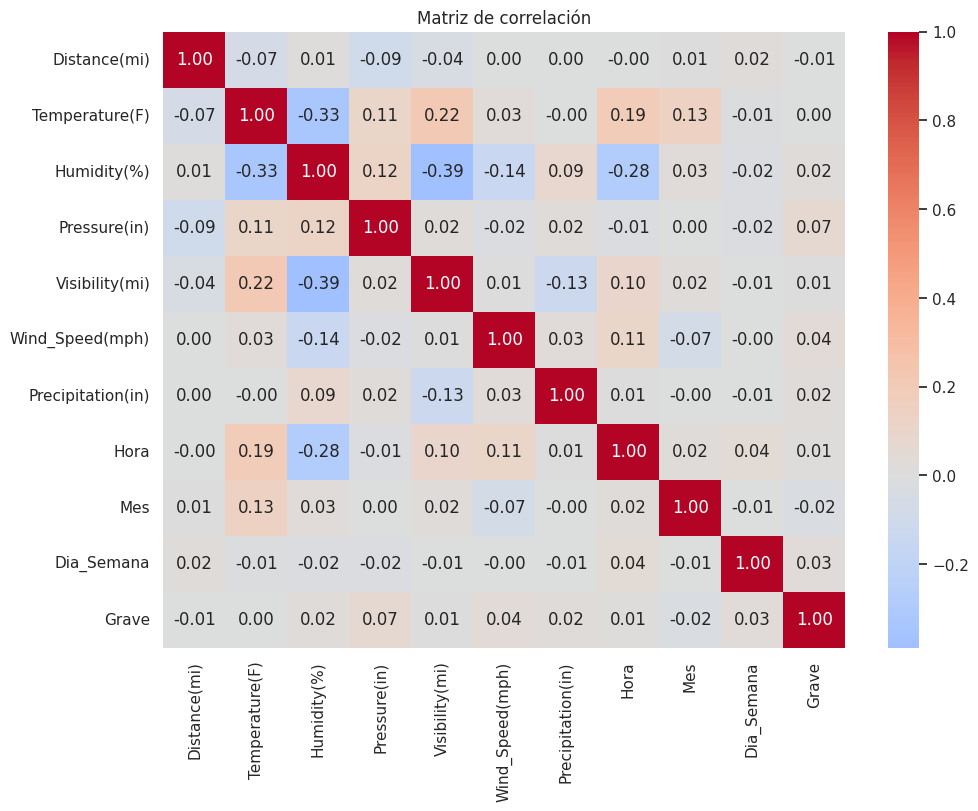

In [ ]:
# Variables numéricas para correlación

variables_corr = [
    "Distance(mi)",
    "Temperature(F)",
    "Humidity(%)",
    "Pressure(in)",
    "Visibility(mi)",
    "Wind_Speed(mph)",
    "Precipitation(in)",
    "Hora",
    "Mes",
    "Dia_Semana",
    "Grave"
]

correlaciones = df_muestra[variables_corr].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlaciones,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Matriz de correlación")
plt.show()

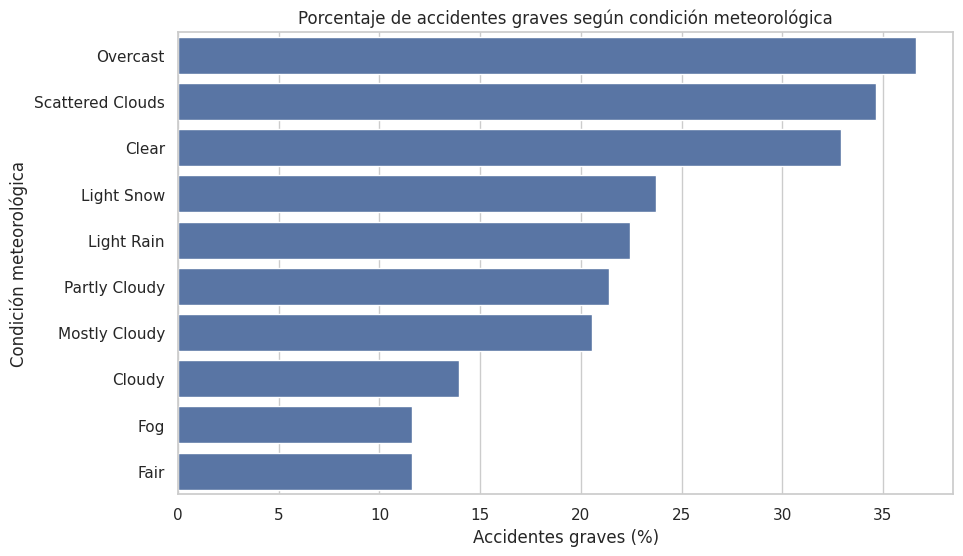

In [ ]:
# Las 10 condiciones meteorológicas más frecuentes

top_climas = (
    df_muestra["Weather_Condition"]
    .value_counts()
    .head(10)
    .index
)

clima = df_muestra[
    df_muestra["Weather_Condition"].isin(top_climas)
]

gravedad_clima = (
    clima
    .groupby("Weather_Condition")["Grave"]
    .mean()
    .sort_values(ascending=False) * 100
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=gravedad_clima.values,
    y=gravedad_clima.index
)

plt.title("Porcentaje de accidentes graves según condición meteorológica")
plt.xlabel("Accidentes graves (%)")
plt.ylabel("Condición meteorológica")

plt.show()

<Figure size 800x600 with 0 Axes>

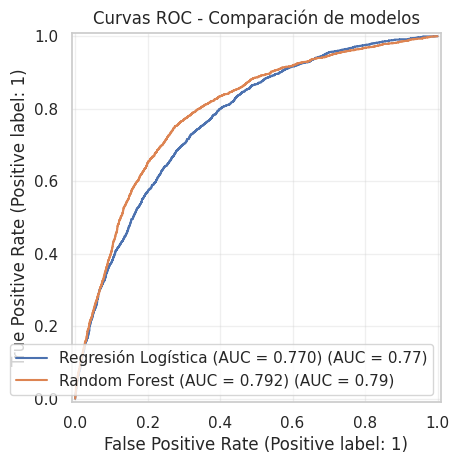

In [ ]:
from sklearn.metrics import RocCurveDisplay

plt.figure(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_log,
    name=f"Regresión Logística (AUC = {roc_auc_log:.3f})"
)

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_rf,
    name=f"Random Forest (AUC = {roc_auc_rf:.3f})",
    ax=plt.gca()
)

plt.title("Curvas ROC - Comparación de modelos")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# Obtener nombres de características después del preprocesamiento

preprocesador_rf = modelo_rf.named_steps["preprocesamiento"]

nombres_features = preprocesador_rf.get_feature_names_out()

# Obtener importancias
rf_entrenado = modelo_rf.named_steps["modelo"]

importancias = rf_entrenado.feature_importances_

tabla_importancias = pd.DataFrame({
    "Variable": nombres_features,
    "Importancia": importancias
})

tabla_importancias = (
    tabla_importancias
    .sort_values("Importancia", ascending=False)
    .reset_index(drop=True)
)

display(tabla_importancias.head(15))

,Variable,Importancia
0,numericas__Distance(mi),0.139274
1,categoricas__Weather_Condition_Fair,0.049030
2,categoricas__Crossing_True,0.043722
3,categoricas__Crossing_False,0.043006
4,categoricas__Traffic_Signal_True,0.041046
5,numericas__Wind_Speed(mph),0.039325
6,categoricas__Weather_Condition_Clear,0.036010
7,categoricas__Traffic_Signal_False,0.034591
8,numericas__Pressure(in),0.032317
9,numericas__Hora,0.024942


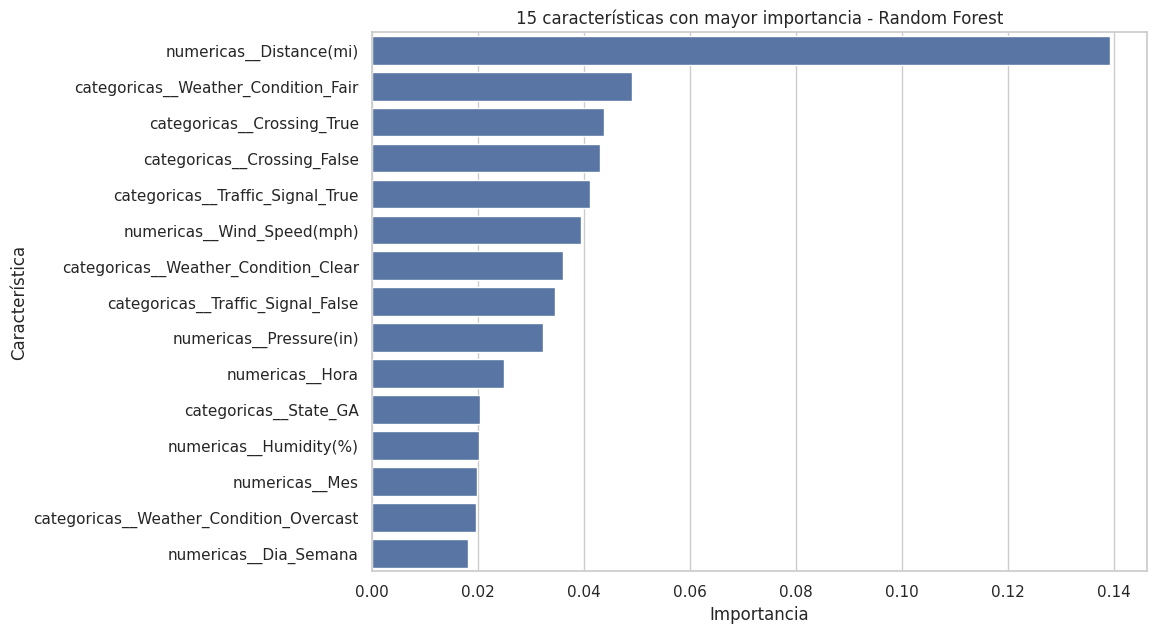

In [ ]:
top15 = tabla_importancias.head(15).copy()

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top15,
    x="Importancia",
    y="Variable"
)

plt.title("15 características con mayor importancia - Random Forest")
plt.xlabel("Importancia")
plt.ylabel("Característica")

plt.show()

In [ ]:
tn_rf, fp_rf, fn_rf, tp_rf = confusion_matrix(
    y_test,
    y_pred_rf
).ravel()

print("MATRIZ DE COSTO / ERROR - RANDOM FOREST")
print("---------------------------------------")
print("Verdaderos negativos (TN):", tn_rf)
print("Falsos positivos (FP):    ", fp_rf)
print("Falsos negativos (FN):    ", fn_rf)
print("Verdaderos positivos (TP):", tp_rf)

print("\nInterpretación:")
print("FP = Accidentes no graves clasificados como graves.")
print("FN = Accidentes graves clasificados como no graves.")

MATRIZ DE COSTO / ERROR - RANDOM FOREST
---------------------------------------
Verdaderos negativos (TN): 5925
Falsos positivos (FP):     2132
Falsos negativos (FN):     513
Verdaderos positivos (TP): 1430

Interpretación:
FP = Accidentes no graves clasificados como graves.
FN = Accidentes graves clasificados como no graves.


In [ ]:
# Matriz conceptual de costo de errores

matriz_costos = pd.DataFrame({
    "Predicción: No grave": [
        "TN - Costo bajo",
        "FN - Costo ALTO"
    ],
    "Predicción: Grave": [
        "FP - Costo medio",
        "TP - Decisión correcta"
    ]
}, index=[
    "Real: No grave",
    "Real: Grave"
])

print("MATRIZ DE COSTO / RIESGO DEL PROBLEMA")
display(matriz_costos)

print("\nJustificación:")
print(
    "El falso negativo (FN) tiene el mayor costo, ya que representa "
    "un accidente realmente grave que el modelo clasifica como no grave."
)

print(
    "El falso positivo (FP) tiene un costo menor, porque genera una "
    "alerta preventiva adicional, pero no deja sin detectar un accidente grave."
)

MATRIZ DE COSTO / RIESGO DEL PROBLEMA


,Predicción: No grave,Predicción: Grave
Real: No grave,TN - Costo bajo,FP - Costo medio
Real: Grave,FN - Costo ALTO,TP - Decisión correcta



Justificación:
El falso negativo (FN) tiene el mayor costo, ya que representa un accidente realmente grave que el modelo clasifica como no grave.
El falso positivo (FP) tiene un costo menor, porque genera una alerta preventiva adicional, pero no deja sin detectar un accidente grave.


In [ ]:

print("RESUMEN FINAL DEL PROYECTO")


print("\nDataset utilizado:")
print(f"Registros analizados: {len(df_muestra)}")
print(f"Variables originales: 20")

print("\nVariable objetivo:")
print("0 = Accidente no grave (Severity 1-2)")
print("1 = Accidente grave (Severity 3-4)")

print("\nPartición:")
print(f"Entrenamiento: {len(X_train)} registros")
print(f"Prueba: {len(X_test)} registros")

print("\nRESULTADOS EN TEST")
display(resultados)

print("\nVALIDACIÓN CRUZADA (5 FOLDS)")
display(resultados_cv.round(4))

print("\nMATRIZ DE CONFUSIÓN - RANDOM FOREST")
print(f"TN: {tn_rf}")
print(f"FP: {fp_rf}")
print(f"FN: {fn_rf}")
print(f"TP: {tp_rf}")

RESUMEN FINAL DEL PROYECTO

Dataset utilizado:
Registros analizados: 50000
Variables originales: 20

Variable objetivo:
0 = Accidente no grave (Severity 1-2)
1 = Accidente grave (Severity 3-4)

Partición:
Entrenamiento: 40000 registros
Prueba: 10000 registros

RESULTADOS EN TEST


,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Regresión Logística,0.7094,0.3679,0.6902,0.4800,0.7701
1,Random Forest,0.7355,0.4015,0.7360,0.5195,0.7923



VALIDACIÓN CRUZADA (5 FOLDS)


,Modelo,Accuracy promedio,Precision promedio,Recall promedio,F1 promedio,ROC-AUC promedio,F1 desviación
0,Regresión Logística,0.7087,0.3646,0.6717,0.4727,0.7659,0.0059
1,Random Forest,0.7411,0.4062,0.7189,0.5191,0.7933,0.0038



MATRIZ DE CONFUSIÓN - RANDOM FOREST
TN: 5925
FP: 2132
FN: 513
TP: 1430


## Conclusiones del experimento

1. Se desarrolló un pipeline completo de minería de datos siguiendo las primeras fases de la metodología **CRISP-DM**.

2. El problema se formuló como una **clasificación binaria**, distinguiendo entre accidentes **graves** y **no graves**.

3. Se utilizó una partición estratificada de **80% para entrenamiento y 20% para prueba**, conservando la distribución de las clases.

4. Todo el preprocesamiento se realizó dentro de un **Pipeline**, reduciendo el riesgo de fuga de información entre los conjuntos de entrenamiento y prueba.

5. Se compararon dos familias de modelos: **Regresión Logística** y **Random Forest**.

6. En el conjunto de prueba, **Random Forest** obtuvo los siguientes resultados:

   - Accuracy: **0.7355**
   - Precision: **0.4015**
   - Recall: **0.7360**
   - F1-Score: **0.5195**
   - ROC-AUC: **0.7923**

7. En la validación cruzada estratificada de **5 folds**, Random Forest obtuvo un **F1 promedio de 0.5191**, con una desviación estándar de **0.0038**, mostrando resultados estables entre las diferentes particiones.

8. Los **falsos negativos** representan el error de mayor riesgo, debido a que corresponden a accidentes realmente graves que fueron clasificados como no graves.

9. Los resultados muestran que el modelo posee capacidad para identificar patrones relacionados con la gravedad de los accidentes, aunque todavía existe margen de mejora, especialmente en la precisión de la clasificación de accidentes graves.

In [ ]:
bitacora = pd.DataFrame({
    "Elemento": [
        "Semilla",
        "Muestra utilizada",
        "Partición",
        "Estratificación",
        "Validación cruzada",
        "Preprocesamiento",
        "Balanceo",
        "Modelos"
    ],

    "Configuración": [
        "42",
        "50,000 registros",
        "80% Train / 20% Test",
        "Sí, usando la variable Grave",
        "Stratified K-Fold, 5 folds",
        "Imputación + escalado + One-Hot Encoding dentro del Pipeline",
        "class_weight='balanced'",
        "Regresión Logística y Random Forest"
    ]
})

display(bitacora)

,Elemento,Configuración
0,Semilla,42
1,Muestra utilizada,"50,000 registros"
2,Partición,80% Train / 20% Test
3,Estratificación,"Sí, usando la variable Grave"
4,Validación cruzada,"Stratified K-Fold, 5 folds"
5,Preprocesamiento,Imputación + escalado + One-Hot Encoding dentr...
6,Balanceo,class_weight='balanced'
7,Modelos,Regresión Logística y Random Forest



# PROYECTO INTEGRADOR PARCIAL II
## Preparación Avanzada de los Datos y Pipeline Robusto

**Proyecto:** Predicción de la gravedad de accidentes de tránsito mediante técnicas de Minería de Datos.

**INTEGRANTES:**

Estephany Vanessa Delgadillo Salgado

Elias Rivera Pedraza

**Metodología:** CRISP-DM

### 3.1 Ficha del dataset definitivo y preparación para la integración

En este segundo parcial se continuará utilizando el dataset US Accidents, conservando la muestra de 50,000 registros y la partición de entrenamiento y prueba del Parcial I.

Se realizará un análisis avanzado de valores faltantes, valores atípicos, selección de características y optimización de los modelos de clasificación.


In [ ]:

# Verificar los datos del Parcial I

print("Registros originales:", len(df_muestra))
print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))

print("\nVariables predictoras:", X_train.shape[1])
print("Variable objetivo: Grave")

print("\nPrimeros registros:")
display(df_muestra.head())


Registros originales: 50000
Registros de entrenamiento: 40000
Registros de prueba: 10000

Variables predictoras: 21
Variable objetivo: Grave

Primeros registros:


,Severity,Start_Time,Distance(mi),City,State,Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in),Weather_Condition,Amenity,Crossing,Junction,Railway,Station,Stop,Traffic_Signal,Sunrise_Sunset,Grave,Hora,Mes,Dia_Semana
0,1,2020-04-17 09:29:30,0.000,West Palm Beach,FL,78.0,81.0,30.13,10.0,13.0,0.01,Mostly Cloudy,False,False,False,False,False,False,True,Day,0,9.0,4.0,4.0
1,2,NaT,0.045,Roseville,CA,55.0,88.0,29.83,10.0,9.0,0.00,Mostly Cloudy,False,True,False,False,False,True,False,Day,0,NaN,NaN,NaN
2,3,2016-08-12 16:45:00,0.000,Alpharetta,GA,91.0,47.0,29.91,10.0,10.4,NaN,Partly Cloudy,False,True,False,False,False,False,False,Day,1,16.0,8.0,4.0
3,3,2019-09-20 15:22:16,0.000,Tacoma,WA,67.0,84.0,29.78,10.0,3.0,0.00,Cloudy,False,False,False,False,False,False,False,Day,1,15.0,9.0,4.0
4,2,2019-06-03 16:55:43,0.000,Scottsdale,AZ,95.0,16.0,28.53,10.0,6.0,0.00,Fair,False,False,False,False,False,False,False,Day,0,16.0,6.0,0.0


In [ ]:

# Conservar los datos originales del Parcial I

X_train_original = X_train.copy()
X_test_original = X_test.copy()

y_train_original = y_train.copy()
y_test_original = y_test.copy()

# Verificar que no se repitan índices entre entrenamiento y prueba

indices_comunes = set(X_train.index) & set(X_test.index)

print("Registros de entrenamiento:", len(X_train_original))
print("Registros de prueba:", len(X_test_original))
print("Índices compartidos:", len(indices_comunes))

# Guardar los datos para el Parcial II

import joblib

joblib.dump({
    "X_train": X_train_original,
    "X_test": X_test_original,
    "y_train": y_train_original,
    "y_test": y_test_original
}, "/content/particion_parcial1.joblib")

print("Partición del Parcial I guardada correctamente.")


Registros de entrenamiento: 40000
Registros de prueba: 10000
Índices compartidos: 0
Partición del Parcial I guardada correctamente.


In [ ]:

# Ficha técnica del dataset definitivo

ficha_dataset = pd.DataFrame({
    "Característica": [
        "Nombre del dataset",
        "Fuente",
        "Tipo de problema",
        "Registros",
        "Variables originales",
        "Variables predictoras actuales",
        "Variable objetivo",
        "Entrenamiento",
        "Prueba",
        "Semilla"
    ],
    "Descripción": [
        "US Accidents",
        "Kaggle - sobhanmoosavi/us-accidents",
        "Clasificación binaria",
        len(df_muestra),
        20,
        X_train.shape[1],
        "Grave (0 = No grave, 1 = Grave)",
        len(X_train),
        len(X_test),
        42
    ]
})

display(ficha_dataset)


,Característica,Descripción
0,Nombre del dataset,US Accidents
1,Fuente,Kaggle - sobhanmoosavi/us-accidents
2,Tipo de problema,Clasificación binaria
3,Registros,50000
4,Variables originales,20
5,Variables predictoras actuales,21
6,Variable objetivo,"Grave (0 = No grave, 1 = Grave)"
7,Entrenamiento,40000
8,Prueba,10000
9,Semilla,42


In [ ]:

# Diccionario de variables del dataset

diccionario = pd.DataFrame({
    "Variable": df_muestra.columns,
    "Tipo de dato": df_muestra.dtypes.astype(str).values,
    "Valores faltantes": df_muestra.isnull().sum().values,
    "Porcentaje faltante": (
        df_muestra.isnull().mean() * 100
    ).round(2).values,
    "Valores únicos": df_muestra.nunique(dropna=True).values
})

display(diccionario)


,Variable,Tipo de dato,Valores faltantes,Porcentaje faltante,Valores únicos
0,Severity,int64,0,0.00,4
1,Start_Time,datetime64[ns],4811,9.62,45047
2,Distance(mi),float64,0,0.00,4673
3,City,object,0,0.00,5127
4,State,object,0,0.00,49
5,Temperature(F),float64,1061,2.12,528
6,Humidity(%),float64,1126,2.25,98
7,Pressure(in),float64,905,1.81,797
8,Visibility(mi),float64,1136,2.27,42
9,Wind_Speed(mph),float64,3811,7.62,69


In [ ]:

# Información descriptiva de las variables

informacion = {
    "Severity": ("Gravedad original del accidente", "Ordinal", "1 a 4"),
    "Start_Time": ("Fecha y hora del accidente", "Temporal", "Fecha y hora"),
    "Distance(mi)": ("Extensión del accidente", "Razón", "Millas, >= 0"),
    "City": ("Ciudad del accidente", "Nominal", "Categoría"),
    "State": ("Estado del accidente", "Nominal", "Categoría"),
    "Temperature(F)": ("Temperatura ambiental", "Intervalo", "Grados Fahrenheit"),
    "Humidity(%)": ("Humedad relativa", "Razón", "0 a 100%"),
    "Pressure(in)": ("Presión atmosférica", "Razón", "Pulgadas de mercurio"),
    "Visibility(mi)": ("Visibilidad", "Razón", "Millas, >= 0"),
    "Wind_Speed(mph)": ("Velocidad del viento", "Razón", "Millas por hora, >= 0"),
    "Precipitation(in)": ("Precipitación", "Razón", "Pulgadas, >= 0"),
    "Weather_Condition": ("Condición meteorológica", "Nominal", "Categoría"),
    "Amenity": ("Presencia de servicios cercanos", "Nominal", "True / False"),
    "Crossing": ("Presencia de cruce", "Nominal", "True / False"),
    "Junction": ("Presencia de intersección", "Nominal", "True / False"),
    "Railway": ("Presencia de vía ferroviaria", "Nominal", "True / False"),
    "Station": ("Presencia de estación", "Nominal", "True / False"),
    "Stop": ("Presencia de señal de alto", "Nominal", "True / False"),
    "Traffic_Signal": ("Presencia de semáforo", "Nominal", "True / False"),
    "Sunrise_Sunset": ("Periodo del día", "Nominal", "Day / Night"),
    "Grave": ("Gravedad binaria del accidente", "Nominal", "0 / 1"),
    "Hora": ("Hora del accidente", "Discreta", "0 a 23"),
    "Mes": ("Mes del accidente", "Discreta", "1 a 12"),
    "Dia_Semana": ("Día de la semana", "Discreta", "0 a 6")
}

diccionario["Significado"] = diccionario["Variable"].map(
    lambda x: informacion[x][0]
)

diccionario["Escala"] = diccionario["Variable"].map(
    lambda x: informacion[x][1]
)

diccionario["Unidad o rango válido"] = diccionario["Variable"].map(
    lambda x: informacion[x][2]
)

display(diccionario)


,Variable,Tipo de dato,Valores faltantes,Porcentaje faltante,Valores únicos,Significado,Escala,Unidad o rango válido
0,Severity,int64,0,0.00,4,Gravedad original del accidente,Ordinal,1 a 4
1,Start_Time,datetime64[ns],4811,9.62,45047,Fecha y hora del accidente,Temporal,Fecha y hora
2,Distance(mi),float64,0,0.00,4673,Extensión del accidente,Razón,"Millas, >= 0"
3,City,object,0,0.00,5127,Ciudad del accidente,Nominal,Categoría
4,State,object,0,0.00,49,Estado del accidente,Nominal,Categoría
5,Temperature(F),float64,1061,2.12,528,Temperatura ambiental,Intervalo,Grados Fahrenheit
6,Humidity(%),float64,1126,2.25,98,Humedad relativa,Razón,0 a 100%
7,Pressure(in),float64,905,1.81,797,Presión atmosférica,Razón,Pulgadas de mercurio
8,Visibility(mi),float64,1136,2.27,42,Visibilidad,Razón,"Millas, >= 0"
9,Wind_Speed(mph),float64,3811,7.62,69,Velocidad del viento,Razón,"Millas por hora, >= 0"


In [ ]:

# Calcular la huella SHA-256 del dataset original

import hashlib
import os

archivo = os.path.join(path, "US_Accidents_March23.csv")

sha256 = hashlib.sha256()

with open(archivo, "rb") as f:
    for bloque in iter(lambda: f.read(1024 * 1024), b""):
        sha256.update(bloque)

print("Nombre del archivo:", os.path.basename(archivo))
print("Tamaño en MB:", round(os.path.getsize(archivo) / (1024 ** 2), 2))
print("Huella SHA-256:", sha256.hexdigest())


Nombre del archivo: US_Accidents_March23.csv
Tamaño en MB: 2916.51
Huella SHA-256: e3e9f962e3e2289db1bdce91623abbcf9ba4d7bfc1adb091c8aeee6c2639d204


In [ ]:

# Procedencia y licencia del dataset

procedencia = pd.DataFrame({
    "Elemento": [
        "Nombre",
        "Autor",
        "Plataforma",
        "Cobertura temporal",
        "Cobertura geográfica",
        "Licencia",
        "Uso permitido",
        "Archivo original",
        "SHA-256"
    ],
    "Información": [
        "US Accidents (2016-2023)",
        "Sobhan Moosavi",
        "Kaggle",
        "Febrero 2016 - Marzo 2023",
        "49 estados de Estados Unidos",
        "CC BY-NC-SA 4.0",
        "Investigación y uso académico no comercial",
        "US_Accidents_March23.csv",
        sha256.hexdigest()
    ]
})

display(procedencia)


,Elemento,Información
0,Nombre,US Accidents (2016-2023)
1,Autor,Sobhan Moosavi
2,Plataforma,Kaggle
3,Cobertura temporal,Febrero 2016 - Marzo 2023
4,Cobertura geográfica,49 estados de Estados Unidos
5,Licencia,CC BY-NC-SA 4.0
6,Uso permitido,Investigación y uso académico no comercial
7,Archivo original,US_Accidents_March23.csv
8,SHA-256,e3e9f962e3e2289db1bdce91623abbcf9ba4d7bfc1adb0...


In [ ]:

# Fuentes externas candidatas para integración

fuentes_externas = pd.DataFrame({
    "Fuente": [
        "NOAA - Storm Events",
        "FHWA - Highway Statistics"
    ],
    "Información": [
        "Fenómenos meteorológicos extremos",
        "Volumen anual de tránsito vehicular"
    ],
    "Cobertura": [
        "Estados Unidos, datos históricos",
        "Estados Unidos, datos anuales"
    ],
    "Llave candidata": [
        "Estado y fecha",
        "Estado y año"
    ],
    "Estado de integración": [
        "Pendiente de validación",
        "Pendiente de validación"
    ]
})

display(fuentes_externas)


,Fuente,Información,Cobertura,Llave candidata,Estado de integración
0,NOAA - Storm Events,Fenómenos meteorológicos extremos,"Estados Unidos, datos históricos",Estado y fecha,Pendiente de validación
1,FHWA - Highway Statistics,Volumen anual de tránsito vehicular,"Estados Unidos, datos anuales",Estado y año,Pendiente de validación


In [ ]:

# Preparar llaves para integrar fuentes externas

datos_integracion = df_muestra.copy()

datos_integracion["Fecha"] = (
    datos_integracion["Start_Time"].dt.date
)

datos_integracion["Año"] = (
    datos_integracion["Start_Time"].dt.year
)

# Verificar las llaves

print("Registros:", len(datos_integracion))

print("\nValores faltantes en las llaves:")
print(datos_integracion[["State", "Fecha", "Año"]].isnull().sum())

print("\nPrimeros registros:")
display(
    datos_integracion[
        ["State", "Fecha", "Año", "Grave"]
    ].head(10)
)


Registros: 50000

Valores faltantes en las llaves:
State       0
Fecha    4811
Año      4811
dtype: int64

Primeros registros:


,State,Fecha,Año,Grave
0,FL,2020-04-17,2020.0,0
1,CA,NaT,NaN,0
2,GA,2016-08-12,2016.0,1
3,WA,2019-09-20,2019.0,1
4,AZ,2019-06-03,2019.0,0
5,IA,2021-02-04,2021.0,0
6,VA,2022-06-23,2022.0,0
7,GA,2020-09-25,2020.0,1
8,MD,2022-02-04,2022.0,0
9,CA,NaT,NaN,0


In [ ]:

# Verificar la cobertura temporal del dataset

conteo_anual = (
    datos_integracion["Año"]
    .value_counts()
    .sort_index()
)

tabla_anual = pd.DataFrame({
    "Año": conteo_anual.index.astype(int),
    "Accidentes": conteo_anual.values
})

tabla_anual["Porcentaje"] = (
    tabla_anual["Accidentes"] / len(datos_integracion) * 100
).round(2)

print("Distribución de accidentes por año:")
display(tabla_anual)

print("Accidentes sin fecha:",
      datos_integracion["Fecha"].isna().sum())

print("Accidentes con fecha:",
      datos_integracion["Fecha"].notna().sum())

print("Total de accidentes:", len(datos_integracion))


Distribución de accidentes por año:


,Año,Accidentes,Porcentaje
0,2016,2709,5.42
1,2017,4637,9.27
2,2018,5768,11.54
3,2019,6173,12.35
4,2020,7407,14.81
5,2021,9246,18.49
6,2022,8221,16.44
7,2023,1028,2.06


Accidentes sin fecha: 4811
Accidentes con fecha: 45189
Total de accidentes: 50000


In [ ]:

# Buscar archivos oficiales de NOAA

import requests
import re

url_noaa = "https://www.ncei.noaa.gov/pub/data/swdi/stormevents/csvfiles/"

respuesta = requests.get(url_noaa, timeout=60)
respuesta.raise_for_status()

archivos = re.findall(
    r"StormEvents_details-ftp_v[\d.]+_d\d{4}_c\d{8}\.csv\.gz",
    respuesta.text
)

archivos = sorted(set(archivos))

archivos_noaa = []

for año in range(2016, 2024):
    encontrados = [
        archivo for archivo in archivos
        if f"_d{año}_" in archivo
    ]

    if encontrados:
        archivos_noaa.append({
            "Año": año,
            "Archivo": sorted(encontrados)[-1]
        })

tabla_noaa = pd.DataFrame(archivos_noaa)

display(tabla_noaa)

print("Años encontrados:", len(tabla_noaa))


,Año,Archivo
0,2016,StormEvents_details-ftp_v1.0_d2016_c20260323.c...
1,2017,StormEvents_details-ftp_v1.0_d2017_c20260519.c...
2,2018,StormEvents_details-ftp_v1.0_d2018_c20260323.c...
3,2019,StormEvents_details-ftp_v1.0_d2019_c20260323.c...
4,2020,StormEvents_details-ftp_v1.0_d2020_c20260323.c...
5,2021,StormEvents_details-ftp_v1.0_d2021_c20260323.c...
6,2022,StormEvents_details-ftp_v1.0_d2022_c20260625.c...
7,2023,StormEvents_details-ftp_v1.0_d2023_c20260323.c...


Años encontrados: 8


In [ ]:

# Descargar y reunir los datos de NOAA

from io import BytesIO

datos_noaa = []

columnas_noaa = [
    "STATE",
    "BEGIN_DATE_TIME",
    "EVENT_TYPE"
]

for i, fila in tabla_noaa.iterrows():

    archivo = fila["Archivo"]
    url = url_noaa + archivo

    respuesta = requests.get(url, timeout=120)
    respuesta.raise_for_status()

    datos_año = pd.read_csv(
        BytesIO(respuesta.content),
        compression="gzip",
        usecols=columnas_noaa,
        low_memory=False
    )

    datos_año["Año"] = fila["Año"]

    datos_noaa.append(datos_año)

    print("Año descargado:", fila["Año"],
          "- Eventos:", len(datos_año))

noaa = pd.concat(datos_noaa, ignore_index=True)

print("\nTotal de eventos meteorológicos:", len(noaa))

display(noaa.head())


Año descargado: 2016 - Eventos: 56005
Año descargado: 2017 - Eventos: 57041
Año descargado: 2018 - Eventos: 62699
Año descargado: 2019 - Eventos: 67864
Año descargado: 2020 - Eventos: 61281
Año descargado: 2021 - Eventos: 61389
Año descargado: 2022 - Eventos: 69887
Año descargado: 2023 - Eventos: 75593

Total de eventos meteorológicos: 511759


,STATE,EVENT_TYPE,BEGIN_DATE_TIME,Año
0,ILLINOIS,Tornado,22-JUN-16 20:10:00,2016
1,SOUTH CAROLINA,Heavy Rain,15-JUL-16 17:15:00,2016
2,SOUTH CAROLINA,Thunderstorm Wind,15-JUL-16 17:25:00,2016
3,NORTH CAROLINA,Thunderstorm Wind,16-JUL-16 12:46:00,2016
4,TENNESSEE,Thunderstorm Wind,08-JUL-16 17:55:00,2016


In [ ]:

# Normalizar estados y fechas de NOAA

import pandas as pd

# Diccionario de estados de Estados Unidos

estados_abreviaturas = {
    "ALABAMA": "AL",
    "ALASKA": "AK",
    "ARIZONA": "AZ",
    "ARKANSAS": "AR",
    "CALIFORNIA": "CA",
    "COLORADO": "CO",
    "CONNECTICUT": "CT",
    "DELAWARE": "DE",
    "FLORIDA": "FL",
    "GEORGIA": "GA",
    "HAWAII": "HI",
    "IDAHO": "ID",
    "ILLINOIS": "IL",
    "INDIANA": "IN",
    "IOWA": "IA",
    "KANSAS": "KS",
    "KENTUCKY": "KY",
    "LOUISIANA": "LA",
    "MAINE": "ME",
    "MARYLAND": "MD",
    "MASSACHUSETTS": "MA",
    "MICHIGAN": "MI",
    "MINNESOTA": "MN",
    "MISSISSIPPI": "MS",
    "MISSOURI": "MO",
    "MONTANA": "MT",
    "NEBRASKA": "NE",
    "NEVADA": "NV",
    "NEW HAMPSHIRE": "NH",
    "NEW JERSEY": "NJ",
    "NEW MEXICO": "NM",
    "NEW YORK": "NY",
    "NORTH CAROLINA": "NC",
    "NORTH DAKOTA": "ND",
    "OHIO": "OH",
    "OKLAHOMA": "OK",
    "OREGON": "OR",
    "PENNSYLVANIA": "PA",
    "RHODE ISLAND": "RI",
    "SOUTH CAROLINA": "SC",
    "SOUTH DAKOTA": "SD",
    "TENNESSEE": "TN",
    "TEXAS": "TX",
    "UTAH": "UT",
    "VERMONT": "VT",
    "VIRGINIA": "VA",
    "WASHINGTON": "WA",
    "WEST VIRGINIA": "WV",
    "WISCONSIN": "WI",
    "WYOMING": "WY",
    "DISTRICT OF COLUMBIA": "DC"
}

# Convertir nombres de estados a abreviaturas

noaa["State"] = (
    noaa["STATE"]
    .str.upper()
    .str.strip()
    .map(estados_abreviaturas)
)

# Convertir las fechas de NOAA

noaa["Fecha"] = pd.to_datetime(
    noaa["BEGIN_DATE_TIME"],
    format="%d-%b-%y %H:%M:%S",
    errors="coerce"
).dt.date

# Comprobar resultados

print("Eventos totales:", len(noaa))

print("\nEstados sin equivalencia:")
print(noaa["State"].isna().sum())

print("\nFechas no convertidas:")
print(noaa["Fecha"].isna().sum())

print("\nPrimeros registros normalizados:")

display(
    noaa[
        ["STATE", "State", "Fecha", "EVENT_TYPE"]
    ].head(10)
)

# Mostrar estados que no se pudieron convertir

print("\nEstados no reconocidos:")
print(noaa.loc[noaa["State"].isna(), "STATE"].value_counts())


Eventos totales: 511759

Estados sin equivalencia:
24710

Fechas no convertidas:
0

Primeros registros normalizados:


,STATE,State,Fecha,EVENT_TYPE
0,ILLINOIS,IL,2016-06-22,Tornado
1,SOUTH CAROLINA,SC,2016-07-15,Heavy Rain
2,SOUTH CAROLINA,SC,2016-07-15,Thunderstorm Wind
3,NORTH CAROLINA,NC,2016-07-16,Thunderstorm Wind
4,TENNESSEE,TN,2016-07-08,Thunderstorm Wind
5,TENNESSEE,TN,2016-07-08,Thunderstorm Wind
6,TENNESSEE,TN,2016-07-08,Thunderstorm Wind
7,WYOMING,WY,2016-12-04,Winter Storm
8,WYOMING,WY,2016-12-04,Winter Storm
9,WYOMING,WY,2016-12-04,Winter Storm



Estados no reconocidos:
STATE
GULF OF MEXICO    7949
ATLANTIC NORTH    6981
ATLANTIC SOUTH    4704
PUERTO RICO       1656
LAKE MICHIGAN      975
LAKE SUPERIOR      750
LAKE ERIE          692
LAKE HURON         238
LAKE ST CLAIR      224
AMERICAN SAMOA     162
GUAM               143
LAKE ONTARIO       105
E PACIFIC           55
VIRGIN ISLANDS      49
ST LAWRENCE R       14
HAWAII WATERS        8
GULF OF ALASKA       4
GUAM WATERS          1
Name: count, dtype: int64


In [ ]:

# Agrupar eventos meteorológicos por estado y fecha

# Conservar eventos con estado y fecha válidos

noaa_validos = noaa.dropna(
    subset=["State", "Fecha"]
).copy()

# Agrupar eventos

noaa_agrupado = (
    noaa_validos
    .groupby(["State", "Fecha"])
    .agg(
        Cantidad_Eventos_NOAA=("EVENT_TYPE", "size"),
        Tipos_Eventos_NOAA=("EVENT_TYPE", "nunique")
    )
    .reset_index()
)

# Comprobar resultados

print("Eventos originales:", len(noaa))
print("Eventos con estado y fecha válidos:", len(noaa_validos))
print("Combinaciones únicas de estado y fecha:", len(noaa_agrupado))

print("\nLlaves duplicadas después de agrupar:")
print(
    noaa_agrupado.duplicated(
        subset=["State", "Fecha"]
    ).sum()
)

print("\nPrimeros registros agrupados:")
display(noaa_agrupado.head(10))


Eventos originales: 511759
Eventos con estado y fecha válidos: 487049
Combinaciones únicas de estado y fecha: 44427

Llaves duplicadas después de agrupar:
0

Primeros registros agrupados:


,State,Fecha,Cantidad_Eventos_NOAA,Tipos_Eventos_NOAA
0,AK,2016-01-02,4,3
1,AK,2016-01-06,3,1
2,AK,2016-01-16,1,1
3,AK,2016-01-17,1,1
4,AK,2016-01-21,1,1
5,AK,2016-01-24,1,1
6,AK,2016-01-25,7,3
7,AK,2016-01-26,2,2
8,AK,2016-01-27,2,2
9,AK,2016-01-30,1,1


In [ ]:

# Integrar US Accidents con NOAA

accidentes_noaa = datos_integracion.merge(
    noaa_agrupado,
    on=["State", "Fecha"],
    how="left",
    validate="many_to_one",
    indicator=True
)

# Verificar la integración

print("Accidentes originales:", len(datos_integracion))
print("Accidentes después de integrar:", len(accidentes_noaa))

print("\nResultados de la integración:")
display(accidentes_noaa["_merge"].value_counts())

# Porcentaje de accidentes con coincidencia

coincidencias = (
    accidentes_noaa["_merge"] == "both"
).sum()

porcentaje = coincidencias / len(accidentes_noaa) * 100

print("\nAccidentes con coincidencia NOAA:", coincidencias)
print(f"Porcentaje de coincidencia: {porcentaje:.2f}%")

print("\nPrimeros registros integrados:")

display(
    accidentes_noaa[
        [
            "State",
            "Fecha",
            "Grave",
            "Cantidad_Eventos_NOAA",
            "Tipos_Eventos_NOAA"
        ]
    ].head(10)
)

# Comprobar que no aumentaron los registros

assert len(accidentes_noaa) == 50000

print("\nIntegración realizada sin duplicar accidentes.")


Accidentes originales: 50000
Accidentes después de integrar: 50000

Resultados de la integración:


,count
_merge,
left_only,30867
both,19133
right_only,0



Accidentes con coincidencia NOAA: 19133
Porcentaje de coincidencia: 38.27%

Primeros registros integrados:


,State,Fecha,Grave,Cantidad_Eventos_NOAA,Tipos_Eventos_NOAA
0,FL,2020-04-17,0,1.0,1.0
1,CA,NaT,0,NaN,NaN
2,GA,2016-08-12,1,NaN,NaN
3,WA,2019-09-20,1,NaN,NaN
4,AZ,2019-06-03,0,NaN,NaN
5,IA,2021-02-04,0,59.0,3.0
6,VA,2022-06-23,0,1.0,1.0
7,GA,2020-09-25,1,NaN,NaN
8,MD,2022-02-04,0,2.0,1.0
9,CA,NaT,0,NaN,NaN



Integración realizada sin duplicar accidentes.


In [ ]:

# Analizar la cobertura de NOAA por año

accidentes_noaa["Coincidencia_NOAA"] = (
    accidentes_noaa["_merge"] == "both"
)

cobertura_anual = (
    accidentes_noaa
    .groupby("Año", dropna=False)
    .agg(
        Accidentes=("Grave", "size"),
        Coincidencias=("Coincidencia_NOAA", "sum")
    )
    .reset_index()
)

cobertura_anual["Sin_coincidencia"] = (
    cobertura_anual["Accidentes"] -
    cobertura_anual["Coincidencias"]
)

cobertura_anual["Cobertura_%"] = (
    cobertura_anual["Coincidencias"] /
    cobertura_anual["Accidentes"] * 100
).round(2)

print("Cobertura de integración por año:")
display(cobertura_anual)

print("\nTotal de accidentes:", len(accidentes_noaa))
print("Coincidencias NOAA:",
      accidentes_noaa["Coincidencia_NOAA"].sum())


Cobertura de integración por año:


,Año,Accidentes,Coincidencias,Sin_coincidencia,Cobertura_%
0,2016.0,2709,1044,1665,38.54
1,2017.0,4637,1833,2804,39.53
2,2018.0,5768,2366,3402,41.02
3,2019.0,6173,2538,3635,41.11
4,2020.0,7407,3119,4288,42.11
5,2021.0,9246,4001,5245,43.27
6,2022.0,8221,3716,4505,45.20
7,2023.0,1028,516,512,50.19
8,NaN,4811,0,4811,0.00



Total de accidentes: 50000
Coincidencias NOAA: 19133


In [ ]:

# Verificar la integridad de la integración

print("Registros originales:", len(df_muestra))
print("Registros integrados:", len(accidentes_noaa))

# Verificar que la variable objetivo no cambió

objetivo_igual = (
    accidentes_noaa["Grave"].equals(df_muestra["Grave"])
)

print("Variable objetivo conservada:", objetivo_igual)

# Verificar las columnas originales

columnas_originales = df_muestra.columns.tolist()

datos_iguales = accidentes_noaa[
    columnas_originales
].equals(df_muestra[columnas_originales])

print("Datos originales conservados:", datos_iguales)

# Verificar índices de entrenamiento y prueba

indices_train = X_train_original.index
indices_test = X_test_original.index

print("Índices de entrenamiento:", len(indices_train))
print("Índices de prueba:", len(indices_test))

# Comprobaciones finales

assert len(accidentes_noaa) == len(df_muestra)
assert objetivo_igual
assert datos_iguales
assert len(set(indices_train) & set(indices_test)) == 0

print("Integridad de datos verificada correctamente.")


Registros originales: 50000
Registros integrados: 50000
Variable objetivo conservada: True
Datos originales conservados: True
Índices de entrenamiento: 40000
Índices de prueba: 10000
Integridad de datos verificada correctamente.


In [ ]:

# Descargar datos oficiales de FHWA

import pandas as pd

url_fhwa = "https://data.transportation.gov/resource/nps9-3pm2.csv"

# Descargar los registros históricos

fhwa = pd.read_csv(
    url_fhwa,
    storage_options={"User-Agent": "Mozilla/5.0"}
)

print("Registros descargados:", len(fhwa))
print("Columnas:", len(fhwa.columns))

print("\nNombres de las columnas:")
print(fhwa.columns.tolist())

print("\nPrimeros registros:")
display(fhwa.head())


Registros descargados: 1000
Columnas: 5

Nombres de las columnas:
['year', 'state', 'area', 'fclass', 'vmt']

Primeros registros:


,year,state,area,fclass,vmt
0,2023,Alabama,Rural,Interstate,6903334100
1,2023,Alabama,Rural,Other Freeways and Expressways,0
2,2023,Alabama,Rural,Other Principal Arterial,5798631330
3,2023,Alabama,Rural,Minor Arterial,4655664000
4,2023,Alabama,Rural,Major Collector,4437644400


In [ ]:

# Descargar los datos completos de FHWA entre 2016 y 2023

import requests
import pandas as pd

url_fhwa = "https://data.transportation.gov/resource/nps9-3pm2.json"

registros_fhwa = []
limite = 10000
offset = 0

while True:
    parametros = {
        "$where": "year between 2016 and 2023",
        "$order": "year, state, area, fclass",
        "$limit": limite,
        "$offset": offset
    }

    respuesta = requests.get(
        url_fhwa,
        params=parametros,
        timeout=120
    )

    respuesta.raise_for_status()
    datos = respuesta.json()

    if len(datos) == 0:
        break

    registros_fhwa.extend(datos)

    print("Registros acumulados:", len(registros_fhwa))

    if len(datos) < limite:
        break

    offset += limite

fhwa_completo = pd.DataFrame(registros_fhwa)

# Convertir las columnas numéricas

fhwa_completo["year"] = pd.to_numeric(
    fhwa_completo["year"], errors="coerce"
)

fhwa_completo["vmt"] = pd.to_numeric(
    fhwa_completo["vmt"], errors="coerce"
)

print("\nTotal de registros:", len(fhwa_completo))

print("\nRegistros por año:")
print(fhwa_completo["year"].value_counts().sort_index())

print("\nPrimeros registros:")
display(fhwa_completo.head())


Registros acumulados: 5824

Total de registros: 5824

Registros por año:
year
2016    728
2017    728
2018    728
2019    728
2020    728
2021    728
2022    728
2023    728
Name: count, dtype: int64

Primeros registros:


,year,state,area,fclass,vmt
0,2016,Alabama,Rural,Interstate,6.332840e+09
1,2016,Alabama,Rural,Local,7.036216e+09
2,2016,Alabama,Rural,Major Collector,4.393736e+09
3,2016,Alabama,Rural,Minor Arterial,4.526700e+09
4,2016,Alabama,Rural,Minor Collector,1.356660e+09


In [ ]:

# Preparar y agrupar los datos de FHWA

# Crear una copia de los datos

fhwa_limpio = fhwa_completo.copy()

# Convertir nombres de estados a abreviaturas

fhwa_limpio["State"] = (
    fhwa_limpio["state"]
    .str.upper()
    .str.strip()
    .map(estados_abreviaturas)
)

# Revisar combinaciones repetidas

duplicados_fhwa = fhwa_limpio.duplicated(
    subset=["year", "State", "area", "fclass"]
).sum()

print("Registros originales:", len(fhwa_limpio))
print("Combinaciones duplicadas:", duplicados_fhwa)
print("Estados sin equivalencia:", fhwa_limpio["State"].isna().sum())

# Agrupar por estado y año

fhwa_agrupado = (
    fhwa_limpio
    .dropna(subset=["State", "year", "vmt"])
    .groupby(["State", "year"], as_index=False)
    .agg(
        VMT_Total=("vmt", "sum")
    )
)

fhwa_agrupado = fhwa_agrupado.rename(
    columns={"year": "Año"}
)

# Comprobar resultados

print("\nRegistros agrupados:", len(fhwa_agrupado))

print("Llaves duplicadas:",
      fhwa_agrupado.duplicated(
          subset=["State", "Año"]
      ).sum())

print("\nPrimeros registros:")
display(fhwa_agrupado.head(10))


Registros originales: 5824
Combinaciones duplicadas: 0
Estados sin equivalencia: 112

Registros agrupados: 408
Llaves duplicadas: 0

Primeros registros:


,State,Año,VMT_Total
0,AK,2016,5.258556e+09
1,AK,2017,5.518716e+09
2,AK,2018,5.487320e+09
3,AK,2019,5.881303e+09
4,AK,2020,5.305889e+09
5,AK,2021,5.752188e+09
6,AK,2022,5.478209e+09
7,AK,2023,5.617229e+09
8,AL,2016,6.922697e+10
9,AL,2017,7.067725e+10


In [ ]:

# Integrar FHWA con US Accidents y NOAA

accidentes_integrados = accidentes_noaa.merge(
    fhwa_agrupado,
    on=["State", "Año"],
    how="left",
    validate="many_to_one",
    indicator="Integracion_FHWA"
)

# Verificar los registros

print("Accidentes originales:", len(df_muestra))
print("Accidentes integrados:", len(accidentes_integrados))

print("\nResultados de la integración FHWA:")
display(accidentes_integrados["Integracion_FHWA"].value_counts())

# Calcular el porcentaje de coincidencia

coincidencias_fhwa = (
    accidentes_integrados["Integracion_FHWA"] == "both"
).sum()

porcentaje_fhwa = (
    coincidencias_fhwa / len(accidentes_integrados)
) * 100

print("\nAccidentes con coincidencia FHWA:", coincidencias_fhwa)
print(f"Porcentaje de coincidencia: {porcentaje_fhwa:.2f}%")

# Mostrar los datos integrados

display(
    accidentes_integrados[
        [
            "State",
            "Año",
            "Grave",
            "Cantidad_Eventos_NOAA",
            "Tipos_Eventos_NOAA",
            "VMT_Total"
        ]
    ].head(10)
)

# Verificar que no se duplicaron los accidentes

assert len(accidentes_integrados) == 50000

print("\nIntegración completada sin duplicar accidentes.")


Accidentes originales: 50000
Accidentes integrados: 50000

Resultados de la integración FHWA:


,count
Integracion_FHWA,
both,45189
left_only,4811
right_only,0



Accidentes con coincidencia FHWA: 45189
Porcentaje de coincidencia: 90.38%


,State,Año,Grave,Cantidad_Eventos_NOAA,Tipos_Eventos_NOAA,VMT_Total
0,FL,2020.0,0,1.0,1.0,2.080759e+11
1,CA,NaN,0,NaN,NaN,NaN
2,GA,2016.0,1,NaN,NaN,1.228022e+11
3,WA,2019.0,1,NaN,NaN,6.252964e+10
4,AZ,2019.0,0,NaN,NaN,7.028065e+10
5,IA,2021.0,0,59.0,3.0,3.303928e+10
6,VA,2022.0,0,1.0,1.0,8.208323e+10
7,GA,2020.0,1,NaN,NaN,1.159668e+11
8,MD,2022.0,0,2.0,1.0,5.674583e+10
9,CA,NaN,0,NaN,NaN,NaN



Integración completada sin duplicar accidentes.


In [ ]:

from google.colab import drive
import os

drive.mount("/content/drive")

carpeta = "/content/drive/MyDrive/Proyecto_Mineria_Parcial_II"

os.makedirs(carpeta, exist_ok=True)

print("Carpeta de respaldo:", carpeta)
print("Google Drive conectado correctamente.")

# Respaldar los objetos calculados en las celdas anteriores
import joblib

respaldos = {
    "particion_parcial1.joblib": {
        "X_train": X_train_original, "X_test": X_test_original,
        "y_train": y_train_original, "y_test": y_test_original
    },
    "datos_integracion_base.joblib": datos_integracion,
    "noaa_original.joblib": noaa,
    "noaa_agrupado.joblib": noaa_agrupado,
    "fhwa_original.joblib": fhwa_completo,
    "fhwa_agrupado.joblib": fhwa_agrupado
}

for nombre, contenido in respaldos.items():
    destino = os.path.join(carpeta, nombre)
    if not os.path.exists(destino):
        joblib.dump(contenido, destino)
    print("Respaldo:", nombre, os.path.exists(destino))


In [ ]:

# Reconstruir la integración de las tres bases de datos

import pandas as pd
import joblib
import os

# Integrar los datos de NOAA

accidentes_noaa = datos_integracion.merge(
    noaa_agrupado,
    on=["State", "Fecha"],
    how="left",
    validate="many_to_one",
    indicator="Integracion_NOAA"
)

# Integrar los datos de FHWA

accidentes_integrados = accidentes_noaa.merge(
    fhwa_agrupado,
    on=["State", "Año"],
    how="left",
    validate="many_to_one",
    indicator="Integracion_FHWA"
)

# Verificar los registros

print("Accidentes originales:", len(df_muestra))
print("Accidentes integrados:", len(accidentes_integrados))

print("\nCoincidencias NOAA:")
print(accidentes_integrados["Integracion_NOAA"].value_counts())

print("\nCoincidencias FHWA:")
print(accidentes_integrados["Integracion_FHWA"].value_counts())

# Verificar la integridad

columnas_originales = df_muestra.columns.tolist()

datos_iguales = accidentes_integrados[
    columnas_originales
].equals(df_muestra[columnas_originales])

print("\nDatos originales conservados:", datos_iguales)

assert len(accidentes_integrados) == 50000
assert datos_iguales

# Guardar respaldo en Google Drive

ruta_final = os.path.join(
    carpeta,
    "accidentes_integrados.joblib"
)

joblib.dump(accidentes_integrados, ruta_final)

print("Respaldo guardado:", os.path.exists(ruta_final))

print("\nPrimeros registros integrados:")

display(
    accidentes_integrados[
        [
            "State",
            "Fecha",
            "Año",
            "Grave",
            "Cantidad_Eventos_NOAA",
            "Tipos_Eventos_NOAA",
            "VMT_Total"
        ]
    ].head(10)
)


Accidentes originales: 50000
Accidentes integrados: 50000

Coincidencias NOAA:
Integracion_NOAA
left_only     30867
both          19133
right_only        0
Name: count, dtype: int64

Coincidencias FHWA:
Integracion_FHWA
both          45189
left_only      4811
right_only        0
Name: count, dtype: int64

Datos originales conservados: True
Respaldo guardado: True

Primeros registros integrados:


,State,Fecha,Año,Grave,Cantidad_Eventos_NOAA,Tipos_Eventos_NOAA,VMT_Total
0,FL,2020-04-17,2020.0,0,1.0,1.0,2.080759e+11
1,CA,NaT,NaN,0,NaN,NaN,NaN
2,GA,2016-08-12,2016.0,1,NaN,NaN,1.228022e+11
3,WA,2019-09-20,2019.0,1,NaN,NaN,6.252964e+10
4,AZ,2019-06-03,2019.0,0,NaN,NaN,7.028065e+10
5,IA,2021-02-04,2021.0,0,59.0,3.0,3.303928e+10
6,VA,2022-06-23,2022.0,0,1.0,1.0,8.208323e+10
7,GA,2020-09-25,2020.0,1,NaN,NaN,1.159668e+11
8,MD,2022-02-04,2022.0,0,2.0,1.0,5.674583e+10
9,CA,NaT,NaN,0,NaN,NaN,NaN


In [ ]:

# Diagnóstico inicial de valores faltantes

import pandas as pd

# Crear una copia para el análisis

df_diagnostico = accidentes_integrados.copy()

# Calcular valores faltantes

tabla_faltantes = pd.DataFrame({
    "Variable": df_diagnostico.columns,
    "Valores_Faltantes": df_diagnostico.isnull().sum().values,
    "Porcentaje": (
        df_diagnostico.isnull().mean() * 100
    ).round(2).values
})

# Ordenar de mayor a menor porcentaje

tabla_faltantes = tabla_faltantes.sort_values(
    by="Porcentaje",
    ascending=False
).reset_index(drop=True)

print("DIAGNÓSTICO DE VALORES FALTANTES")

display(tabla_faltantes)

# Resumen general

print("\nRegistros:", len(df_diagnostico))
print("Columnas:", len(df_diagnostico.columns))
print("Variables con valores faltantes:",
      (tabla_faltantes["Valores_Faltantes"] > 0).sum())


DIAGNÓSTICO DE VALORES FALTANTES


,Variable,Valores_Faltantes,Porcentaje
0,Tipos_Eventos_NOAA,30867,61.73
1,Cantidad_Eventos_NOAA,30867,61.73
2,Precipitation(in),14375,28.75
3,Mes,4811,9.62
4,Hora,4811,9.62
5,Start_Time,4811,9.62
6,Dia_Semana,4811,9.62
7,Año,4811,9.62
8,VMT_Total,4811,9.62
9,Fecha,4811,9.62



Registros: 50000
Columnas: 31
Variables con valores faltantes: 17


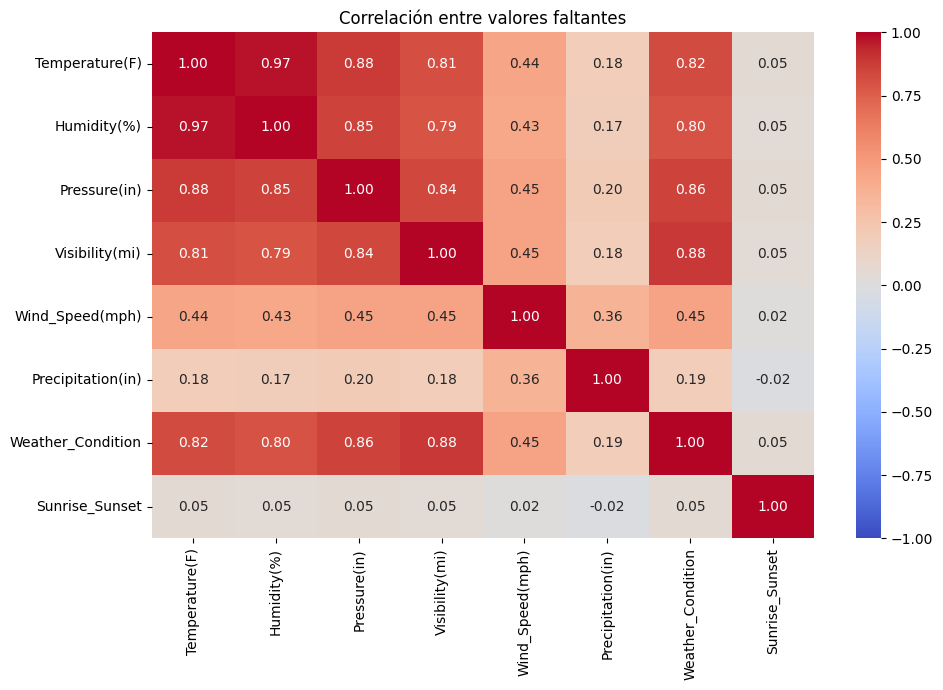

Registros con al menos un faltante: 15407
Registros completos: 34593


In [ ]:

# Analizar patrones de valores faltantes

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

variables_analisis = [
    "Temperature(F)",
    "Humidity(%)",
    "Pressure(in)",
    "Visibility(mi)",
    "Wind_Speed(mph)",
    "Precipitation(in)",
    "Weather_Condition",
    "Sunrise_Sunset"
]

# Crear matriz de ausencia

matriz_faltantes = (
    df_diagnostico[variables_analisis]
    .isnull()
    .astype(int)
)

# Calcular correlación entre indicadores de ausencia

correlacion_faltantes = matriz_faltantes.corr()

# Visualizar correlaciones

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlacion_faltantes,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlación entre valores faltantes")
plt.tight_layout()
plt.show()

# Contar registros con faltantes

registros_faltantes = matriz_faltantes.any(axis=1).sum()

print("Registros con al menos un faltante:",
      registros_faltantes)

print("Registros completos:",
      len(matriz_faltantes) - registros_faltantes)


In [ ]:

# Analizar la relación entre faltantes y variables observadas

import pandas as pd
from scipy.stats import chi2_contingency

variables_faltantes = [
    "Temperature(F)",
    "Humidity(%)",
    "Pressure(in)",
    "Visibility(mi)",
    "Wind_Speed(mph)",
    "Precipitation(in)",
    "Weather_Condition",
    "Sunrise_Sunset"
]

resultados_ausencia = []

for variable in variables_faltantes:

    indicador = df_diagnostico[variable].isna()

    for explicativa in ["State", "Año"]:

        tabla = pd.crosstab(
            df_diagnostico[explicativa].fillna("Desconocido").astype(str),
            indicador
        )

        if tabla.shape[1] == 2:
            chi2, p, grados, esperados = chi2_contingency(tabla)

            resultados_ausencia.append({
                "Variable": variable,
                "Relacionada_con": explicativa,
                "Chi2": round(chi2, 2),
                "p_valor": p,
                "Asociacion_significativa": p < 0.05
            })

tabla_mecanismos = pd.DataFrame(resultados_ausencia)

display(tabla_mecanismos)


,Variable,Relacionada_con,Chi2,p_valor,Asociacion_significativa
0,Temperature(F),State,827.56,1.248012e-142,True
1,Temperature(F),Año,31.23,1.277950e-04,True
2,Humidity(%),State,786.88,2.672487e-134,True
3,Humidity(%),Año,35.20,2.455507e-05,True
4,Pressure(in),State,882.59,6.140086e-154,True
5,Pressure(in),Año,31.70,1.053236e-04,True
6,Visibility(mi),State,1342.86,1.061006e-249,True
7,Visibility(mi),Año,38.91,5.118761e-06,True
8,Wind_Speed(mph),State,711.68,5.696935e-119,True
9,Wind_Speed(mph),Año,3678.94,0.000000e+00,True


In [ ]:

# Preparar datos para los experimentos de imputación

import pandas as pd
import numpy as np

# Recuperar la partición original

X_train_imp = X_train_original.copy()
X_test_imp = X_test_original.copy()

y_train_imp = y_train_original.copy()
y_test_imp = y_test_original.copy()

# Seleccionar variables numéricas con faltantes

columnas_imputacion = [
    "Temperature(F)",
    "Humidity(%)",
    "Pressure(in)",
    "Visibility(mi)",
    "Wind_Speed(mph)",
    "Precipitation(in)",
    "Hora",
    "Mes",
    "Dia_Semana"
]

# Verificar las variables

print("Entrenamiento:", X_train_imp.shape)
print("Prueba:", X_test_imp.shape)

print("\nValores faltantes en entrenamiento:")

tabla_train = pd.DataFrame({
    "Variable": columnas_imputacion,
    "Faltantes": X_train_imp[
        columnas_imputacion
    ].isna().sum().values,
    "Porcentaje": (
        X_train_imp[columnas_imputacion]
        .isna().mean() * 100
    ).round(2).values
})

display(tabla_train)

# Comprobar que conservamos los mismos índices

assert X_train_imp.index.equals(X_train_original.index)
assert X_test_imp.index.equals(X_test_original.index)

print("Partición original conservada correctamente.")


Entrenamiento: (40000, 21)
Prueba: (10000, 21)

Valores faltantes en entrenamiento:


,Variable,Faltantes,Porcentaje
0,Temperature(F),862,2.15
1,Humidity(%),915,2.29
2,Pressure(in),733,1.83
3,Visibility(mi),915,2.29
4,Wind_Speed(mph),3052,7.63
5,Precipitation(in),11462,28.66
6,Hora,3842,9.60
7,Mes,3842,9.60
8,Dia_Semana,3842,9.60


Partición original conservada correctamente.


In [ ]:

# Preparar experimento de imputación

import numpy as np
import pandas as pd

# Utilizar solamente entrenamiento

datos_reales = X_train_imp[
    columnas_imputacion
].copy()

datos_ocultos = datos_reales.copy()

# Guardar los valores que ocultaremos

posiciones_ocultas = {}
valores_originales = {}

generador = np.random.default_rng(42)

for columna in columnas_imputacion:

    # Buscar registros con valores conocidos
    disponibles = datos_reales[
        columna
    ].dropna().index.to_numpy()

    # Seleccionar el 10%
    cantidad = int(len(disponibles) * 0.10)

    seleccionados = generador.choice(
        disponibles,
        size=cantidad,
        replace=False
    )

    # Guardar posiciones y valores reales
    posiciones_ocultas[columna] = seleccionados

    valores_originales[columna] = datos_reales.loc[
        seleccionados, columna
    ].copy()

    # Ocultar los valores
    datos_ocultos.loc[
        seleccionados, columna
    ] = np.nan

# Mostrar resultados

tabla_ocultamiento = pd.DataFrame({
    "Variable": columnas_imputacion,
    "Valores ocultados": [
        len(posiciones_ocultas[c])
        for c in columnas_imputacion
    ],
    "Faltantes después": [
        datos_ocultos[c].isna().sum()
        for c in columnas_imputacion
    ]
})

display(tabla_ocultamiento)

print("Experimento preparado correctamente.")


,Variable,Valores ocultados,Faltantes después
0,Temperature(F),3913,4775
1,Humidity(%),3908,4823
2,Pressure(in),3926,4659
3,Visibility(mi),3908,4823
4,Wind_Speed(mph),3694,6746
5,Precipitation(in),2853,14315
6,Hora,3615,7457
7,Mes,3615,7457
8,Dia_Semana,3615,7457


Experimento preparado correctamente.


In [ ]:

# Comparar imputación por media y mediana

from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

resultados_imputacion = []

for metodo in ["mean", "median"]:

    imputador = SimpleImputer(strategy=metodo)

    datos_imputados = pd.DataFrame(
        imputador.fit_transform(datos_ocultos),
        columns=columnas_imputacion,
        index=datos_ocultos.index
    )

    for columna in columnas_imputacion:

        posiciones = posiciones_ocultas[columna]

        reales = valores_originales[columna].values
        estimados = datos_imputados.loc[
            posiciones, columna
        ].values

        mae = mean_absolute_error(reales, estimados)
        rmse = np.sqrt(mean_squared_error(reales, estimados))

        resultados_imputacion.append({
            "Método": metodo,
            "Variable": columna,
            "MAE": round(mae, 4),
            "RMSE": round(rmse, 4)
        })

tabla_resultados = pd.DataFrame(resultados_imputacion)

display(tabla_resultados)

print("Comparación de media y mediana completada.")


,Método,Variable,MAE,RMSE
0,mean,Temperature(F),15.2812,18.7780
1,mean,Humidity(%),19.0896,22.7864
2,mean,Pressure(in),0.6348,1.0945
3,mean,Visibility(mi),1.5966,2.7664
4,mean,Wind_Speed(mph),4.0735,5.2829
5,mean,Precipitation(in),0.0163,0.1911
6,mean,Hora,4.6949,5.4748
7,mean,Mes,3.2191,3.6508
8,mean,Dia_Semana,1.5528,1.8129
9,median,Temperature(F),15.1631,18.8943


Comparación de media y mediana completada.


In [ ]:

# Imputación KNN con 5 vecinos

from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np

# Escalar utilizando los valores disponibles

escalador = StandardScaler()

datos_escalados = pd.DataFrame(
    escalador.fit_transform(datos_ocultos),
    columns=columnas_imputacion,
    index=datos_ocultos.index
)

# Imputación KNN

imputador_knn = KNNImputer(
    n_neighbors=5,
    weights="distance"
)

datos_knn_escalados = imputador_knn.fit_transform(
    datos_escalados
)

# Recuperar las unidades originales

datos_knn = pd.DataFrame(
    escalador.inverse_transform(datos_knn_escalados),
    columns=columnas_imputacion,
    index=datos_ocultos.index
)

# Evaluar los valores ocultados

resultados_knn = []

for columna in columnas_imputacion:

    posiciones = posiciones_ocultas[columna]

    reales = valores_originales[columna].values
    estimados = datos_knn.loc[posiciones, columna].values

    mae = mean_absolute_error(reales, estimados)
    rmse = np.sqrt(mean_squared_error(reales, estimados))

    resultados_knn.append({
        "Método": "KNN (K=5)",
        "Variable": columna,
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4)
    })

tabla_knn = pd.DataFrame(resultados_knn)

display(tabla_knn)

print("Imputación KNN completada.")


,Método,Variable,MAE,RMSE
0,KNN (K=5),Temperature(F),16.2076,20.2609
1,KNN (K=5),Humidity(%),19.5620,24.3138
2,KNN (K=5),Pressure(in),0.7606,1.2953
3,KNN (K=5),Visibility(mi),1.5697,3.2583
4,KNN (K=5),Wind_Speed(mph),4.8505,6.3406
5,KNN (K=5),Precipitation(in),0.0121,0.1915
6,KNN (K=5),Hora,5.3082,6.4790
7,KNN (K=5),Mes,3.5081,4.1679
8,KNN (K=5),Dia_Semana,1.8234,2.2512


Imputación KNN completada.


In [ ]:

# Imputación iterativa

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np

# Crear el imputador iterativo

imputador_iterativo = IterativeImputer(
    max_iter=10,
    random_state=42,
    initial_strategy="median"
)

# Imputar valores faltantes

datos_iterativos = pd.DataFrame(
    imputador_iterativo.fit_transform(datos_ocultos),
    columns=columnas_imputacion,
    index=datos_ocultos.index
)

# Evaluar los valores ocultados

resultados_iterativos = []

for columna in columnas_imputacion:

    posiciones = posiciones_ocultas[columna]

    reales = valores_originales[columna].values
    estimados = datos_iterativos.loc[posiciones, columna].values

    mae = mean_absolute_error(reales, estimados)
    rmse = np.sqrt(mean_squared_error(reales, estimados))

    resultados_iterativos.append({
        "Método": "Iterativa",
        "Variable": columna,
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4)
    })

tabla_iterativa = pd.DataFrame(resultados_iterativos)

display(tabla_iterativa)

print("Imputación iterativa completada.")


,Método,Variable,MAE,RMSE
0,Iterativa,Temperature(F),13.9180,17.1915
1,Iterativa,Humidity(%),15.6447,19.4867
2,Iterativa,Pressure(in),0.6268,1.0781
3,Iterativa,Visibility(mi),1.5353,2.5456
4,Iterativa,Wind_Speed(mph),3.9839,5.1747
5,Iterativa,Precipitation(in),0.0171,0.1910
6,Iterativa,Hora,4.2790,5.2278
7,Iterativa,Mes,3.1306,3.6056
8,Iterativa,Dia_Semana,1.5484,1.8091


Imputación iterativa completada.


In [ ]:

# Comparación general de métodos de imputación

import pandas as pd
import numpy as np

# Unir los resultados anteriores

comparacion_imputacion = pd.concat(
    [
        tabla_resultados,
        tabla_knn,
        tabla_iterativa
    ],
    ignore_index=True
)

# Identificar el mejor método por variable

mejor_mae = comparacion_imputacion.loc[
    comparacion_imputacion.groupby("Variable")["MAE"].idxmin()
]

mejor_rmse = comparacion_imputacion.loc[
    comparacion_imputacion.groupby("Variable")["RMSE"].idxmin()
]

print("Mejor método según MAE:")
display(mejor_mae[["Variable", "Método", "MAE"]])

print("\nMejor método según RMSE:")
display(mejor_rmse[["Variable", "Método", "RMSE"]])

# Comparar la varianza después de la imputación

metodos_datos = {
    "Media": SimpleImputer(strategy="mean").fit_transform(datos_ocultos),
    "Mediana": SimpleImputer(strategy="median").fit_transform(datos_ocultos),
    "KNN": datos_knn.values,
    "Iterativa": datos_iterativos.values
}

resultados_varianza = []

for metodo, valores in metodos_datos.items():

    datos_metodo = pd.DataFrame(
        valores,
        columns=columnas_imputacion,
        index=datos_ocultos.index
    )

    for columna in columnas_imputacion:

        varianza_original = datos_reales[columna].var()
        varianza_imputada = datos_metodo[columna].var()

        cambio = (
            (varianza_imputada - varianza_original)
            / varianza_original * 100
        )

        resultados_varianza.append({
            "Método": metodo,
            "Variable": columna,
            "Cambio_varianza_%": round(cambio, 2)
        })

tabla_varianza = pd.DataFrame(resultados_varianza)

print("\nCambio porcentual de varianza:")
display(tabla_varianza)


Mejor método según MAE:


,Variable,Método,MAE
17,Dia_Semana,median,1.5477
33,Hora,Iterativa,4.2790
28,Humidity(%),Iterativa,15.6447
34,Mes,Iterativa,3.1306
14,Precipitation(in),median,0.0104
11,Pressure(in),median,0.5606
27,Temperature(F),Iterativa,13.9180
12,Visibility(mi),median,1.0475
31,Wind_Speed(mph),Iterativa,3.9839



Mejor método según RMSE:


,Variable,Método,RMSE
35,Dia_Semana,Iterativa,1.8091
33,Hora,Iterativa,5.2278
28,Humidity(%),Iterativa,19.4867
34,Mes,Iterativa,3.6056
32,Precipitation(in),Iterativa,0.1910
29,Pressure(in),Iterativa,1.0781
27,Temperature(F),Iterativa,17.1915
30,Visibility(mi),Iterativa,2.5456
31,Wind_Speed(mph),Iterativa,5.1747



Cambio porcentual de varianza:


,Método,Variable,Cambio_varianza_%
0,Media,Temperature(F),-11.59
1,Media,Humidity(%),-12.02
2,Media,Pressure(in),-13.15
3,Media,Visibility(mi),-12.38
4,Media,Wind_Speed(mph),-13.27
5,Media,Precipitation(in),-58.06
6,Media,Hora,-18.62
7,Media,Mes,-18.78
8,Media,Dia_Semana,-18.73
9,Mediana,Temperature(F),-11.40


In [ ]:

# Evaluar eliminación por listas

import pandas as pd

# Trabajar solamente con el conjunto de entrenamiento

datos_completos = X_train_imp.dropna()

# Conservar las etiquetas correspondientes

y_completos = y_train_imp.loc[datos_completos.index]

# Calcular registros eliminados

total = len(X_train_imp)
conservados = len(datos_completos)
eliminados = total - conservados

porcentaje_eliminado = eliminados / total * 100

print("Registros originales:", total)
print("Registros conservados:", conservados)
print("Registros eliminados:", eliminados)
print(f"Porcentaje eliminado: {porcentaje_eliminado:.2f}%")

# Comparar la distribución de clases

distribucion = pd.DataFrame({
    "Entrenamiento original": (
        y_train_imp.value_counts(normalize=True) * 100
    ),
    "Después de eliminación": (
        y_completos.value_counts(normalize=True) * 100
    )
}).round(2)

distribucion.index = ["No grave (0)", "Grave (1)"]

print("\nDistribución de clases (%):")
display(distribucion)

# Guardar resumen

resumen_eliminacion = pd.DataFrame({
    "Método": ["Eliminación por listas"],
    "Registros originales": [total],
    "Registros conservados": [conservados],
    "Registros eliminados": [eliminados],
    "Porcentaje eliminado": [round(porcentaje_eliminado, 2)]
})

display(resumen_eliminacion)


Registros originales: 40000
Registros conservados: 24138
Registros eliminados: 15862
Porcentaje eliminado: 39.66%

Distribución de clases (%):


,Entrenamiento original,Después de eliminación
No grave (0),80.56,84.06
Grave (1),19.43,15.94


,Método,Registros originales,Registros conservados,Registros eliminados,Porcentaje eliminado
0,Eliminación por listas,40000,24138,15862,39.66


In [ ]:

# Validación cruzada con imputación por media y mediana

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd

# Identificar variables

numericas = X_train_imp.select_dtypes(
    include=["number"]
).columns.tolist()

categoricas = X_train_imp.select_dtypes(
    include=["object", "bool", "category"]
).columns.tolist()

# Configurar validación cruzada

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

resultados_cv_imputacion = []

for metodo in ["mean", "median"]:

    pipeline_numerico = Pipeline([
        ("imputador", SimpleImputer(strategy=metodo)),
        ("escalador", StandardScaler())
    ])

    pipeline_categorico = Pipeline([
        ("imputador", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocesador = ColumnTransformer([
        ("numericas", pipeline_numerico, numericas),
        ("categoricas", pipeline_categorico, categoricas)
    ])

    modelo = Pipeline([
        ("preprocesador", preprocesador),
        ("clasificador", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ])

    evaluacion = cross_validate(
        modelo,
        X_train_imp,
        y_train_imp,
        cv=cv,
        scoring={
            "Accuracy": "accuracy",
            "Precision": "precision",
            "Recall": "recall",
            "F1": "f1",
            "ROC_AUC": "roc_auc"
        },
        n_jobs=2
    )

    resultados_cv_imputacion.append({
        "Método": metodo,
        "Accuracy": evaluacion["test_Accuracy"].mean(),
        "Precision": evaluacion["test_Precision"].mean(),
        "Recall": evaluacion["test_Recall"].mean(),
        "F1": evaluacion["test_F1"].mean(),
        "ROC_AUC": evaluacion["test_ROC_AUC"].mean(),
        "F1_std": evaluacion["test_F1"].std()
    })

tabla_cv_imputacion = pd.DataFrame(
    resultados_cv_imputacion
)

display(tabla_cv_imputacion.round(4))


,Método,Accuracy,Precision,Recall,F1,ROC_AUC,F1_std
0,mean,0.7094,0.3652,0.6715,0.4731,0.7660,0.0052
1,median,0.7087,0.3646,0.6717,0.4727,0.7659,0.0059


In [ ]:

# Validación cruzada con imputación iterativa

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
import pandas as pd

# Pipeline numérico

pipeline_numerico = Pipeline([
    ("imputador", IterativeImputer(
        max_iter=10,
        random_state=42,
        initial_strategy="median"
    )),
    ("escalador", StandardScaler())
])

# Pipeline categórico

pipeline_categorico = Pipeline([
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Preprocesamiento

preprocesador = ColumnTransformer([
    ("numericas", pipeline_numerico, numericas),
    ("categoricas", pipeline_categorico, categoricas)
])

# Modelo

modelo_iterativo = Pipeline([
    ("preprocesador", preprocesador),
    ("clasificador", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Validación cruzada

evaluacion = cross_validate(
    modelo_iterativo,
    X_train_imp,
    y_train_imp,
    cv=cv,
    scoring={
        "Accuracy": "accuracy",
        "Precision": "precision",
        "Recall": "recall",
        "F1": "f1",
        "ROC_AUC": "roc_auc"
    },
    n_jobs=2
)

resultado_iterativo_cv = pd.DataFrame([{
    "Método": "Iterativa",
    "Accuracy": evaluacion["test_Accuracy"].mean(),
    "Precision": evaluacion["test_Precision"].mean(),
    "Recall": evaluacion["test_Recall"].mean(),
    "F1": evaluacion["test_F1"].mean(),
    "ROC_AUC": evaluacion["test_ROC_AUC"].mean(),
    "F1_std": evaluacion["test_F1"].std()
}])

# Agregar resultado a la comparación

tabla_cv_imputacion = pd.concat(
    [tabla_cv_imputacion, resultado_iterativo_cv],
    ignore_index=True
)

display(tabla_cv_imputacion.round(4))

# Guardar respaldo en Google Drive

ruta_cv = carpeta + "/resultados_cv_imputacion.csv"

tabla_cv_imputacion.to_csv(ruta_cv, index=False)

print("Resultados guardados correctamente.")


,Método,Accuracy,Precision,Recall,F1,ROC_AUC,F1_std
0,mean,0.7094,0.3652,0.6715,0.4731,0.7660,0.0052
1,median,0.7087,0.3646,0.6717,0.4727,0.7659,0.0059
2,Iterativa,0.7097,0.3656,0.6715,0.4734,0.7659,0.0056


Resultados guardados correctamente.


In [ ]:

# Validación cruzada con imputación KNN

from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
import pandas as pd

# Pipeline numérico

pipeline_numerico = Pipeline([
    ("escalador", StandardScaler()),
    ("imputador", KNNImputer(
        n_neighbors=5,
        weights="distance"
    ))
])

# Pipeline categórico

pipeline_categorico = Pipeline([
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Preprocesamiento

preprocesador_knn = ColumnTransformer([
    ("numericas", pipeline_numerico, numericas),
    ("categoricas", pipeline_categorico, categoricas)
])

# Modelo de clasificación

modelo_knn_imp = Pipeline([
    ("preprocesador", preprocesador_knn),
    ("clasificador", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Validación cruzada

evaluacion_knn = cross_validate(
    modelo_knn_imp,
    X_train_imp,
    y_train_imp,
    cv=cv,
    scoring={
        "Accuracy": "accuracy",
        "Precision": "precision",
        "Recall": "recall",
        "F1": "f1",
        "ROC_AUC": "roc_auc"
    },
    n_jobs=1
)

# Guardar resultados

resultado_knn_cv = pd.DataFrame([{
    "Método": "KNN (K=5)",
    "Accuracy": evaluacion_knn["test_Accuracy"].mean(),
    "Precision": evaluacion_knn["test_Precision"].mean(),
    "Recall": evaluacion_knn["test_Recall"].mean(),
    "F1": evaluacion_knn["test_F1"].mean(),
    "ROC_AUC": evaluacion_knn["test_ROC_AUC"].mean(),
    "F1_std": evaluacion_knn["test_F1"].std()
}])

tabla_cv_imputacion = pd.concat(
    [tabla_cv_imputacion, resultado_knn_cv],
    ignore_index=True
)

display(tabla_cv_imputacion.round(4))

# Guardar respaldo en Google Drive

tabla_cv_imputacion.to_csv(
    carpeta + "/resultados_cv_imputacion.csv",
    index=False
)

print("Validación KNN completada y guardada.")


,Método,Accuracy,Precision,Recall,F1,ROC_AUC,F1_std
0,mean,0.7094,0.3652,0.6715,0.4731,0.7660,0.0052
1,median,0.7087,0.3646,0.6717,0.4727,0.7659,0.0059
2,Iterativa,0.7097,0.3656,0.6715,0.4734,0.7659,0.0056
3,KNN (K=5),0.7095,0.3656,0.6730,0.4738,0.7665,0.0066


Validación KNN completada y guardada.


In [ ]:

# Validación cruzada con eliminación por listas

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import numpy as np
import pandas as pd

resultados_listwise = []

for indice_train, indice_val in cv.split(X_train_imp, y_train_imp):

    X_tr = X_train_imp.iloc[indice_train].copy()
    X_val = X_train_imp.iloc[indice_val].copy()

    y_tr = y_train_imp.iloc[indice_train].copy()
    y_val = y_train_imp.iloc[indice_val].copy()

    # Eliminar filas con valores faltantes

    X_tr = X_tr.dropna()
    X_val = X_val.dropna()

    y_tr = y_tr.loc[X_tr.index]
    y_val = y_val.loc[X_val.index]

    # Preprocesamiento sin imputación

    preprocesador = ColumnTransformer([
        ("numericas", StandardScaler(), numericas),
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), categoricas)
    ])

    modelo = Pipeline([
        ("preprocesador", preprocesador),
        ("clasificador", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ])

    modelo.fit(X_tr, y_tr)

    predicciones = modelo.predict(X_val)
    probabilidades = modelo.predict_proba(X_val)[:, 1]

    resultados_listwise.append({
        "Accuracy": accuracy_score(y_val, predicciones),
        "Precision": precision_score(y_val, predicciones, zero_division=0),
        "Recall": recall_score(y_val, predicciones, zero_division=0),
        "F1": f1_score(y_val, predicciones, zero_division=0),
        "ROC_AUC": roc_auc_score(y_val, probabilidades)
    })

tabla_listwise = pd.DataFrame(resultados_listwise)

resultado_listwise_cv = pd.DataFrame([{
    "Método": "Eliminación por listas",
    "Accuracy": tabla_listwise["Accuracy"].mean(),
    "Precision": tabla_listwise["Precision"].mean(),
    "Recall": tabla_listwise["Recall"].mean(),
    "F1": tabla_listwise["F1"].mean(),
    "ROC_AUC": tabla_listwise["ROC_AUC"].mean(),
    "F1_std": tabla_listwise["F1"].std(ddof=0)
}])

# Agregar a los resultados anteriores

tabla_cv_imputacion = pd.concat(
    [tabla_cv_imputacion, resultado_listwise_cv],
    ignore_index=True
)

print("Comparación de las cinco estrategias:")
display(tabla_cv_imputacion.round(4))

# Guardar resultados en Google Drive

tabla_cv_imputacion.to_csv(
    carpeta + "/resultados_cv_imputacion.csv",
    index=False
)

print("Resultados guardados correctamente.")


Comparación de las cinco estrategias:


,Método,Accuracy,Precision,Recall,F1,ROC_AUC,F1_std
0,mean,0.7094,0.3652,0.6715,0.4731,0.7660,0.0052
1,median,0.7087,0.3646,0.6717,0.4727,0.7659,0.0059
2,Iterativa,0.7097,0.3656,0.6715,0.4734,0.7659,0.0056
3,KNN (K=5),0.7095,0.3656,0.6730,0.4738,0.7665,0.0066
4,Eliminación por listas,0.7022,0.2956,0.6286,0.4021,0.7390,0.0078


Resultados guardados correctamente.


In [ ]:

# Detectar valores atípicos con el método de Tukey

import pandas as pd

variables_atipicos = [
    "Distance(mi)",
    "Temperature(F)",
    "Humidity(%)",
    "Pressure(in)",
    "Visibility(mi)",
    "Wind_Speed(mph)",
    "Precipitation(in)"
]

resultados_atipicos = []

for columna in variables_atipicos:

    datos = X_train_original[columna].dropna()

    q1 = datos.quantile(0.25)
    q3 = datos.quantile(0.75)

    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    atipicos = (
        (datos < limite_inferior) |
        (datos > limite_superior)
    ).sum()

    resultados_atipicos.append({
        "Variable": columna,
        "Q1": round(q1, 4),
        "Q3": round(q3, 4),
        "IQR": round(iqr, 4),
        "Límite inferior": round(limite_inferior, 4),
        "Límite superior": round(limite_superior, 4),
        "Atípicos": atipicos,
        "Porcentaje": round(atipicos / len(datos) * 100, 2)
    })

tabla_atipicos = pd.DataFrame(resultados_atipicos)

display(tabla_atipicos)

print("Detección de valores atípicos completada.")


,Variable,Q1,Q3,IQR,Límite inferior,Límite superior,Atípicos,Porcentaje
0,Distance(mi),0.00,0.461,0.461,-0.6915,1.1525,5048,12.62
1,Temperature(F),49.00,76.000,27.000,8.5000,116.5000,273,0.70
2,Humidity(%),48.00,84.000,36.000,-6.0000,138.0000,0,0.00
3,Pressure(in),29.37,30.030,0.660,28.3800,31.0200,2367,6.03
4,Visibility(mi),10.00,10.000,0.000,10.0000,10.0000,7728,19.77
5,Wind_Speed(mph),4.60,10.400,5.800,-4.1000,19.1000,1044,2.83
6,Precipitation(in),0.00,0.000,0.000,0.0000,0.0000,2771,9.71


Detección de valores atípicos completada.


In [ ]:

# Detectar valores atípicos mediante Z-score robusto

import numpy as np
import pandas as pd

resultados_zscore = []

for columna in variables_atipicos:

    datos = X_train_original[columna].dropna()

    mediana = datos.median()

    mad = np.median(
        np.abs(datos - mediana)
    )

    if mad > 0:
        z_robusto = (
            0.6745 * (datos - mediana) / mad
        )

        atipicos = (np.abs(z_robusto) > 3.5).sum()
        porcentaje = atipicos / len(datos) * 100
        estado = "Calculado"

    else:
        atipicos = np.nan
        porcentaje = np.nan
        estado = "MAD igual a cero"

    resultados_zscore.append({
        "Variable": columna,
        "Mediana": round(mediana, 4),
        "MAD": round(mad, 4),
        "Atípicos": atipicos,
        "Porcentaje": round(porcentaje, 2),
        "Estado": estado
    })

tabla_zscore = pd.DataFrame(resultados_zscore)

display(tabla_zscore)

print("Detección mediante Z-score robusto completada.")


,Variable,Mediana,MAD,Atípicos,Porcentaje,Estado
0,Distance(mi),0.03,0.03,14275.0,35.69,Calculado
1,Temperature(F),64.00,13.00,74.0,0.19,Calculado
2,Humidity(%),67.00,18.00,0.0,0.00,Calculado
3,Pressure(in),29.85,0.25,2718.0,6.92,Calculado
4,Visibility(mi),10.00,0.00,NaN,NaN,MAD igual a cero
5,Wind_Speed(mph),7.00,3.00,403.0,1.09,Calculado
6,Precipitation(in),0.00,0.00,NaN,NaN,MAD igual a cero


Detección mediante Z-score robusto completada.


In [ ]:

# Detectar valores atípicos mediante Mahalanobis

import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.covariance import LedoitWolf
from scipy.stats import chi2

# Variables para el análisis multivariado

variables_mahalanobis = [
    "Temperature(F)",
    "Humidity(%)",
    "Pressure(in)",
    "Visibility(mi)",
    "Wind_Speed(mph)"
]

# Utilizar solamente entrenamiento

datos_mahalanobis = X_train_original[
    variables_mahalanobis
].copy()

# Imputar valores faltantes con mediana

imputador = SimpleImputer(strategy="median")

datos_limpios = imputador.fit_transform(
    datos_mahalanobis
)

# Estandarizar variables

from sklearn.preprocessing import StandardScaler

escalador = StandardScaler()

datos_escalados = escalador.fit_transform(
    datos_limpios
)

# Estimar matriz de covarianza

estimador = LedoitWolf()
estimador.fit(datos_escalados)

# Calcular distancia de Mahalanobis al cuadrado

diferencias = datos_escalados - estimador.location_

distancias = np.sum(
    (diferencias @ estimador.precision_) * diferencias,
    axis=1
)

# Umbral con distribución chi-cuadrada

umbral = chi2.ppf(
    0.99,
    df=len(variables_mahalanobis)
)

# Detectar valores extremos

atipicos_mahalanobis = distancias > umbral

cantidad = atipicos_mahalanobis.sum()
porcentaje = cantidad / len(distancias) * 100

print("Registros analizados:", len(distancias))
print("Variables utilizadas:", len(variables_mahalanobis))
print("Umbral:", round(umbral, 4))
print("Atípicos detectados:", cantidad)
print(f"Porcentaje: {porcentaje:.2f}%")

# Guardar resultados

tabla_mahalanobis = pd.DataFrame({
    "Distancia_Mahalanobis_2": distancias,
    "Atipico": atipicos_mahalanobis
}, index=X_train_original.index)

display(tabla_mahalanobis.head(10))


Registros analizados: 40000
Variables utilizadas: 5
Umbral: 15.0863
Atípicos detectados: 1438
Porcentaje: 3.60%


,Distancia_Mahalanobis_2,Atipico
6423,2.332409,False
2224,2.944712,False
6449,0.663458,False
7012,3.043883,False
22053,1.180511,False
4468,4.069327,False
32388,4.381909,False
21735,2.539534,False
28336,1.322402,False
27112,9.137336,False


In [ ]:

# Comparar métodos de detección de valores atípicos

import pandas as pd
import numpy as np

# Resultados de Tukey

comparacion_tukey = tabla_atipicos[
    ["Variable", "Atípicos", "Porcentaje"]
].copy()

comparacion_tukey["Método"] = "Tukey (IQR)"

# Resultados de Z-score robusto

comparacion_zscore = tabla_zscore[
    ["Variable", "Atípicos", "Porcentaje"]
].copy()

comparacion_zscore["Método"] = "Z-score robusto"

# Resultados de Mahalanobis

comparacion_mahalanobis = pd.DataFrame({
    "Variable": ["Conjunto de 5 variables"],
    "Atípicos": [int(atipicos_mahalanobis.sum())],
    "Porcentaje": [round(
        atipicos_mahalanobis.mean() * 100, 2
    )],
    "Método": ["Mahalanobis"]
})

# Unir resultados

comparacion_atipicos = pd.concat(
    [
        comparacion_tukey,
        comparacion_zscore,
        comparacion_mahalanobis
    ],
    ignore_index=True
)

# Ordenar columnas

comparacion_atipicos = comparacion_atipicos[
    ["Método", "Variable", "Atípicos", "Porcentaje"]
]

print("Comparación de métodos de detección:")
display(comparacion_atipicos)

# Guardar en Google Drive

ruta_atipicos = carpeta + "/comparacion_atipicos.csv"

comparacion_atipicos.to_csv(
    ruta_atipicos,
    index=False
)

print("Resultados guardados correctamente.")


Comparación de métodos de detección:


,Método,Variable,Atípicos,Porcentaje
0,Tukey (IQR),Distance(mi),5048.0,12.62
1,Tukey (IQR),Temperature(F),273.0,0.70
2,Tukey (IQR),Humidity(%),0.0,0.00
3,Tukey (IQR),Pressure(in),2367.0,6.03
4,Tukey (IQR),Visibility(mi),7728.0,19.77
5,Tukey (IQR),Wind_Speed(mph),1044.0,2.83
6,Tukey (IQR),Precipitation(in),2771.0,9.71
7,Z-score robusto,Distance(mi),14275.0,35.69
8,Z-score robusto,Temperature(F),74.0,0.19
9,Z-score robusto,Humidity(%),0.0,0.00


Resultados guardados correctamente.


In [ ]:

# Preparar tratamientos de valores atípicos

import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import RobustScaler, StandardScaler

# Transformador para limitar valores extremos

class Winsorizador(BaseEstimator, TransformerMixin):

    def __init__(self, inferior=0.01, superior=0.99):
        self.inferior = inferior
        self.superior = superior

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)

        self.limite_inferior_ = np.nanquantile(
            X, self.inferior, axis=0
        )

        self.limite_superior_ = np.nanquantile(
            X, self.superior, axis=0
        )

        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)

        return np.clip(
            X,
            self.limite_inferior_,
            self.limite_superior_
        )

# Definir los tres tratamientos

tratamientos_atipicos = {
    "Sin tratamiento": StandardScaler(),
    "Winsorización": Winsorizador(
        inferior=0.01,
        superior=0.99
    ),
    "Escalado robusto": RobustScaler()
}

print("Tratamientos preparados:")

for nombre in tratamientos_atipicos:
    print(nombre)

print("\nTransformadores creados correctamente.")


Tratamientos preparados:
Sin tratamiento
Winsorización
Escalado robusto

Transformadores creados correctamente.


In [ ]:

# Comparar tratamientos de valores atípicos

import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

resultados_tratamientos = []

for tratamiento in [
    "Sin tratamiento",
    "Winsorización",
    "Escalado robusto"
]:

    pasos_numericos = [
        ("imputador", SimpleImputer(strategy="median"))
    ]

    if tratamiento == "Winsorización":
        pasos_numericos.append(
            ("winsorizador", Winsorizador())
        )
        pasos_numericos.append(
            ("escalador", StandardScaler())
        )

    elif tratamiento == "Escalado robusto":
        pasos_numericos.append(
            ("escalador", RobustScaler())
        )

    else:
        pasos_numericos.append(
            ("escalador", StandardScaler())
        )

    pipeline_numerico = Pipeline(pasos_numericos)

    pipeline_categorico = Pipeline([
        ("imputador", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocesador = ColumnTransformer([
        ("numericas", pipeline_numerico, numericas),
        ("categoricas", pipeline_categorico, categoricas)
    ])

    modelo = Pipeline([
        ("preprocesador", preprocesador),
        ("clasificador", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ])

    evaluacion = cross_validate(
        modelo,
        X_train_imp,
        y_train_imp,
        cv=cv,
        scoring={
            "Accuracy": "accuracy",
            "Precision": "precision",
            "Recall": "recall",
            "F1": "f1",
            "ROC_AUC": "roc_auc"
        },
        n_jobs=2
    )

    resultados_tratamientos.append({
        "Tratamiento": tratamiento,
        "Accuracy": evaluacion["test_Accuracy"].mean(),
        "Precision": evaluacion["test_Precision"].mean(),
        "Recall": evaluacion["test_Recall"].mean(),
        "F1": evaluacion["test_F1"].mean(),
        "ROC_AUC": evaluacion["test_ROC_AUC"].mean(),
        "F1_std": evaluacion["test_F1"].std()
    })

    print("Evaluado:", tratamiento)

tabla_tratamientos = pd.DataFrame(resultados_tratamientos)

print("\nComparación de tratamientos:")
display(tabla_tratamientos.round(4))

# Guardar resultados en Google Drive

tabla_tratamientos.to_csv(
    carpeta + "/resultados_tratamientos_atipicos.csv",
    index=False
)

print("Resultados guardados correctamente.")


Evaluado: Sin tratamiento
Evaluado: Winsorización
Evaluado: Escalado robusto

Comparación de tratamientos:


,Tratamiento,Accuracy,Precision,Recall,F1,ROC_AUC,F1_std
0,Sin tratamiento,0.7087,0.3646,0.6717,0.4727,0.7659,0.0059
1,Winsorización,0.7104,0.3665,0.6726,0.4744,0.7679,0.0051
2,Escalado robusto,0.7088,0.3645,0.6706,0.4723,0.7658,0.0055


Resultados guardados correctamente.


In [ ]:

# Selección de características mediante información mutua

import pandas as pd

from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer

# Preparar variables numéricas

numericas = X_train_original.select_dtypes(
    include=["number"]
).columns.tolist()

categoricas = X_train_original.select_dtypes(
    include=["object", "bool", "category"]
).columns.tolist()

# Preprocesamiento para información mutua

preprocesador_mi = ColumnTransformer([
    ("numericas", SimpleImputer(strategy="median"), numericas),
    ("categoricas", Pipeline([
        ("imputador", SimpleImputer(strategy="most_frequent")),
        ("codificador", OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ))
    ]), categoricas)
])

X_mi = preprocesador_mi.fit_transform(X_train_original)

# Calcular información mutua

importancias_mi = mutual_info_classif(
    X_mi,
    y_train_original,
    random_state=42
)

# Crear tabla de resultados

nombres_variables = numericas + categoricas

tabla_mi = pd.DataFrame({
    "Variable": nombres_variables,
    "Información mutua": importancias_mi
})

tabla_mi = tabla_mi.sort_values(
    by="Información mutua",
    ascending=False
).reset_index(drop=True)

print("Importancia de características:")
display(tabla_mi)

# Guardar en Google Drive

tabla_mi.to_csv(
    carpeta + "/seleccion_informacion_mutua.csv",
    index=False
)

print("Resultados guardados correctamente.")


Importancia de características:


,Variable,Información mutua
0,City,0.047791
1,Distance(mi),0.045918
2,State,0.027091
3,Wind_Speed(mph),0.024504
4,Weather_Condition,0.019180
5,Temperature(F),0.016427
6,Traffic_Signal,0.011113
7,Mes,0.007978
8,Crossing,0.006673
9,Pressure(in),0.006348


Resultados guardados correctamente.


In [ ]:

# Comparar diferentes cantidades de características

import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from functools import partial

# Preparar las variables

numericas = X_train_original.select_dtypes(
    include=["number"]
).columns.tolist()

categoricas = X_train_original.select_dtypes(
    include=["object", "bool", "category"]
).columns.tolist()

pipeline_numerico = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler())
])

pipeline_categorico = Pipeline([
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("codificador", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

preprocesador = ColumnTransformer([
    ("numericas", pipeline_numerico, numericas),
    ("categoricas", pipeline_categorico, categoricas)
])

resultados_seleccion = []

for k in [5, 10, 15, 21]:

    modelo = Pipeline([
        ("preprocesador", preprocesador),
        ("seleccion", SelectKBest(
            score_func=partial(
                mutual_info_classif,
                random_state=42
            ),
            k=k
        )),
        ("clasificador", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ])

    evaluacion = cross_validate(
        modelo,
        X_train_original,
        y_train_original,
        cv=cv,
        scoring={
            "Accuracy": "accuracy",
            "Precision": "precision",
            "Recall": "recall",
            "F1": "f1",
            "ROC_AUC": "roc_auc"
        },
        n_jobs=2
    )

    resultados_seleccion.append({
        "Características": k,
        "Accuracy": evaluacion["test_Accuracy"].mean(),
        "Precision": evaluacion["test_Precision"].mean(),
        "Recall": evaluacion["test_Recall"].mean(),
        "F1": evaluacion["test_F1"].mean(),
        "ROC_AUC": evaluacion["test_ROC_AUC"].mean()
    })

    print("Evaluadas:", k, "características")

tabla_seleccion = pd.DataFrame(resultados_seleccion)

print("\nComparación de selección de características:")
display(tabla_seleccion.round(4))

tabla_seleccion.to_csv(
    carpeta + "/resultados_seleccion_caracteristicas.csv",
    index=False
)

print("Resultados guardados correctamente.")


Evaluadas: 5 características
Evaluadas: 10 características
Evaluadas: 15 características
Evaluadas: 21 características

Comparación de selección de características:


,Características,Accuracy,Precision,Recall,F1,ROC_AUC
0,5,0.5809,0.2342,0.5096,0.3209,0.5624
1,10,0.5386,0.2415,0.6418,0.3509,0.6179
2,15,0.5425,0.2496,0.6752,0.3644,0.6356
3,21,0.5451,0.2524,0.6834,0.3687,0.6426


Resultados guardados correctamente.


In [ ]:

# Selección embebida con Random Forest

import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

# Preprocesamiento

pipeline_numerico = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler())
])

pipeline_categorico = Pipeline([
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

resultados_embebido = []

for k in [5, 10, 15, 21]:

    preprocesador = ColumnTransformer([
        ("numericas", pipeline_numerico, numericas),
        ("categoricas", pipeline_categorico, categoricas)
    ])

    selector = SelectFromModel(
        RandomForestClassifier(
            n_estimators=100,
            max_depth=10,
            random_state=42,
            n_jobs=1
        ),
        threshold=-float("inf"),
        max_features=k
    )

    modelo = Pipeline([
        ("preprocesador", preprocesador),
        ("selector", selector),
        ("clasificador", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ])

    evaluacion = cross_validate(
        modelo,
        X_train_original,
        y_train_original,
        cv=cv,
        scoring={
            "Accuracy": "accuracy",
            "Precision": "precision",
            "Recall": "recall",
            "F1": "f1",
            "ROC_AUC": "roc_auc"
        },
        n_jobs=2
    )

    resultados_embebido.append({
        "Características": k,
        "Accuracy": evaluacion["test_Accuracy"].mean(),
        "Precision": evaluacion["test_Precision"].mean(),
        "Recall": evaluacion["test_Recall"].mean(),
        "F1": evaluacion["test_F1"].mean(),
        "ROC_AUC": evaluacion["test_ROC_AUC"].mean()
    })

    print("Evaluadas:", k, "características transformadas")

tabla_embebido = pd.DataFrame(resultados_embebido)

display(tabla_embebido.round(4))

# Guardar resultados

tabla_embebido.to_csv(
    carpeta + "/resultados_seleccion_embebida.csv",
    index=False
)

print("Resultados guardados correctamente.")


Evaluadas: 5 características transformadas
Evaluadas: 10 características transformadas
Evaluadas: 15 características transformadas
Evaluadas: 21 características transformadas


,Características,Accuracy,Precision,Recall,F1,ROC_AUC
0,5,0.5577,0.2692,0.6629,0.3603,0.6576
1,10,0.5639,0.2670,0.7124,0.3884,0.6725
2,15,0.5934,0.2769,0.6776,0.3931,0.6739
3,21,0.6250,0.2915,0.6496,0.4023,0.6896


Resultados guardados correctamente.


In [ ]:

# Selección de características mediante RFE

import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

# Seleccionar variables numéricas

X_rfe = X_train_original[numericas].copy()

resultados_rfe = []

for k in [5, 7, 10]:

    selector = RFE(
        estimator=LogisticRegression(
            max_iter=500,
            class_weight="balanced",
            random_state=42
        ),
        n_features_to_select=k,
        step=1
    )

    modelo = Pipeline([
        ("imputador", SimpleImputer(strategy="median")),
        ("escalador", StandardScaler()),
        ("selector", selector),
        ("clasificador", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ])

    evaluacion = cross_validate(
        modelo,
        X_rfe,
        y_train_original,
        cv=cv,
        scoring={
            "Accuracy": "accuracy",
            "Precision": "precision",
            "Recall": "recall",
            "F1": "f1",
            "ROC_AUC": "roc_auc"
        },
        n_jobs=2
    )

    resultados_rfe.append({
        "Características": k,
        "Accuracy": evaluacion["test_Accuracy"].mean(),
        "Precision": evaluacion["test_Precision"].mean(),
        "Recall": evaluacion["test_Recall"].mean(),
        "F1": evaluacion["test_F1"].mean(),
        "ROC_AUC": evaluacion["test_ROC_AUC"].mean()
    })

    print("Evaluadas:", k, "características")

tabla_rfe = pd.DataFrame(resultados_rfe)

print("\nResultados del método RFE:")
display(tabla_rfe.round(4))

# Guardar resultados en Google Drive

tabla_rfe.to_csv(
    carpeta + "/resultados_seleccion_rfe.csv",
    index=False
)

print("Resultados guardados correctamente.")


Evaluadas: 5 características
Evaluadas: 7 características
Evaluadas: 10 características

Resultados del método RFE:


,Características,Accuracy,Precision,Recall,F1,ROC_AUC
0,5,0.5157,0.2234,0.6026,0.3259,0.5662
1,7,0.5170,0.2233,0.5997,0.3254,0.5667
2,10,0.5169,0.2242,0.6039,0.3269,0.5676


Resultados guardados correctamente.


In [ ]:

# Comparar métodos de selección de características

import pandas as pd

# Recuperar resultados de cada método

filtro = tabla_seleccion.copy()
filtro["Método"] = "Filtro - Información mutua"

embebido = tabla_embebido.copy()
embebido["Método"] = "Embebido - Random Forest"

envolvente = tabla_rfe.copy()
envolvente["Método"] = "Envolvente - RFE"

# Unir resultados

comparacion_seleccion = pd.concat(
    [filtro, embebido, envolvente],
    ignore_index=True
)

# Ordenar columnas

comparacion_seleccion = comparacion_seleccion[
    [
        "Método",
        "Características",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC_AUC"
    ]
]

# Mostrar resultados

print("Comparación de métodos de selección:")
display(comparacion_seleccion.round(4))

# Identificar el mayor F1 de cada método

mejores_seleccion = (
    comparacion_seleccion
    .sort_values("F1", ascending=False)
    .drop_duplicates(subset=["Método"])
)

print("\nMejor configuración de cada método:")
display(mejores_seleccion.round(4))

# Guardar en Google Drive

comparacion_seleccion.to_csv(
    carpeta + "/comparacion_metodos_seleccion.csv",
    index=False
)

print("Resultados guardados correctamente.")


Comparación de métodos de selección:


,Método,Características,Accuracy,Precision,Recall,F1,ROC_AUC
0,Filtro - Información mutua,5,0.5809,0.2342,0.5096,0.3209,0.5624
1,Filtro - Información mutua,10,0.5386,0.2415,0.6418,0.3509,0.6179
2,Filtro - Información mutua,15,0.5425,0.2496,0.6752,0.3644,0.6356
3,Filtro - Información mutua,21,0.5451,0.2524,0.6834,0.3687,0.6426
4,Embebido - Random Forest,5,0.5577,0.2692,0.6629,0.3603,0.6576
5,Embebido - Random Forest,10,0.5639,0.2670,0.7124,0.3884,0.6725
6,Embebido - Random Forest,15,0.5934,0.2769,0.6776,0.3931,0.6739
7,Embebido - Random Forest,21,0.6250,0.2915,0.6496,0.4023,0.6896
8,Envolvente - RFE,5,0.5157,0.2234,0.6026,0.3259,0.5662
9,Envolvente - RFE,7,0.5170,0.2233,0.5997,0.3254,0.5667



Mejor configuración de cada método:


,Método,Características,Accuracy,Precision,Recall,F1,ROC_AUC
7,Embebido - Random Forest,21,0.6250,0.2915,0.6496,0.4023,0.6896
3,Filtro - Información mutua,21,0.5451,0.2524,0.6834,0.3687,0.6426
10,Envolvente - RFE,10,0.5169,0.2242,0.6039,0.3269,0.5676


Resultados guardados correctamente.


In [ ]:

# Construir el pipeline robusto inicial

import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

# Variables continuas para winsorización

continuas = [
    "Distance(mi)",
    "Temperature(F)",
    "Humidity(%)",
    "Pressure(in)",
    "Visibility(mi)",
    "Wind_Speed(mph)",
    "Precipitation(in)"
]

# Variables de tiempo

temporales = [
    "Hora",
    "Mes",
    "Dia_Semana"
]

# Variables categóricas

categoricas = X_train_original.select_dtypes(
    include=["object", "bool", "category"]
).columns.tolist()

# Pipeline continuo

pipeline_continuo = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("winsorizador", Winsorizador(
        inferior=0.01,
        superior=0.99
    )),
    ("escalador", StandardScaler())
])

# Pipeline temporal

pipeline_temporal = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler())
])

# Pipeline categórico

pipeline_categorico = Pipeline([
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Integrar transformaciones

preprocesador_final = ColumnTransformer([
    ("continuas", pipeline_continuo, continuas),
    ("temporales", pipeline_temporal, temporales),
    ("categoricas", pipeline_categorico, categoricas)
])

# Modelo completo

pipeline_robusto = Pipeline([
    ("preprocesador", preprocesador_final),
    ("clasificador", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

print("Pipeline robusto creado correctamente.")

print("Variables continuas:", len(continuas))
print("Variables temporales:", len(temporales))
print("Variables categóricas:", len(categoricas))

print("Total de variables originales:",
      len(continuas) + len(temporales) + len(categoricas))



Pipeline robusto creado correctamente.
Variables continuas: 7
Variables temporales: 3
Variables categóricas: 11
Total de variables originales: 21


In [ ]:

# Evaluar el pipeline robusto con validación cruzada

import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate

cv_robusto = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

metricas = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc"
}

# Evaluar solamente con entrenamiento

evaluacion_robusta = cross_validate(
    pipeline_robusto,
    X_train_original,
    y_train_original,
    cv=cv_robusto,
    scoring=metricas,
    n_jobs=2
)

# Organizar resultados

resultados_robustos = pd.DataFrame({
    "Métrica": list(metricas.keys()),
    "Promedio": [
        evaluacion_robusta["test_" + m].mean()
        for m in metricas
    ],
    "Desviación estándar": [
        evaluacion_robusta["test_" + m].std()
        for m in metricas
    ]
})

print("Resultados del pipeline robusto:")
display(resultados_robustos.round(4))

# Guardar resultados

resultados_robustos.to_csv(
    carpeta + "/resultados_pipeline_robusto.csv",
    index=False
)

print("Resultados guardados correctamente.")


Resultados del pipeline robusto:


,Métrica,Promedio,Desviación estándar
0,Accuracy,0.7104,0.0013
1,Precision,0.3665,0.0029
2,Recall,0.6726,0.0111
3,F1,0.4744,0.0051
4,ROC_AUC,0.7679,0.0058


Resultados guardados correctamente.


In [ ]:

# Optimización de hiperparámetros con GridSearchCV

import pandas as pd
import joblib

from sklearn.model_selection import GridSearchCV

# Configurar los hiperparámetros

parametros = {
    "clasificador__C": [0.01, 0.1, 1, 10],
    "clasificador__class_weight": [None, "balanced"]
}

# Crear la búsqueda

busqueda = GridSearchCV(
    estimator=pipeline_robusto,
    param_grid=parametros,
    scoring="f1",
    cv=cv_robusto,
    n_jobs=2,
    refit=True
)

# Entrenar solamente con TRAIN

busqueda.fit(
    X_train_original,
    y_train_original
)

# Mostrar resultados

print("Mejores hiperparámetros:")
print(busqueda.best_params_)

print("\nMejor F1 promedio:")
print(round(busqueda.best_score_, 4))

# Tabla de todas las configuraciones

tabla_grid = pd.DataFrame(busqueda.cv_results_)

tabla_grid = tabla_grid[
    [
        "param_clasificador__C",
        "param_clasificador__class_weight",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]
]

tabla_grid = tabla_grid.sort_values(
    "rank_test_score"
)

display(tabla_grid.round(4))

# Guardar resultados

tabla_grid.to_csv(
    carpeta + "/resultados_gridsearch.csv",
    index=False
)

joblib.dump(
    busqueda.best_estimator_,
    carpeta + "/mejor_pipeline_logistico.joblib"
)

print("Mejor modelo y resultados guardados correctamente.")


Mejores hiperparámetros:
{'clasificador__C': 1, 'clasificador__class_weight': 'balanced'}

Mejor F1 promedio:
0.4744


,param_clasificador__C,param_clasificador__class_weight,mean_test_score,std_test_score,rank_test_score
5,1.00,balanced,0.4744,0.0051,1
3,0.10,balanced,0.4701,0.0069,2
7,10.00,balanced,0.4700,0.0072,3
1,0.01,balanced,0.4517,0.0065,4
6,10.00,None,0.3371,0.0092,5
4,1.00,None,0.2924,0.0058,6
2,0.10,None,0.2004,0.0111,7
0,0.01,None,0.0638,0.0076,8


Mejor modelo y resultados guardados correctamente.


RESULTADOS DEL PIPELINE OPTIMIZADO EN TEST


,Métrica,Resultado
0,Accuracy,0.7096
1,Precision,0.3677
2,Recall,0.6876
3,F1-Score,0.4792
4,ROC-AUC,0.7717


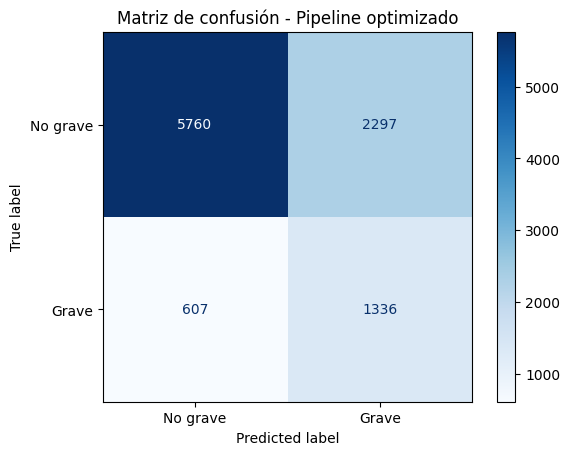

Reporte de clasificación:
              precision    recall  f1-score   support

    No grave       0.90      0.71      0.80      8057
       Grave       0.37      0.69      0.48      1943

    accuracy                           0.71     10000
   macro avg       0.64      0.70      0.64     10000
weighted avg       0.80      0.71      0.74     10000

Resultados finales guardados correctamente.


In [ ]:

# Evaluar el modelo optimizado en TEST

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Utilizar el mejor modelo de GridSearchCV

modelo_final = busqueda.best_estimator_

# Predicciones en los datos de prueba

y_pred_final = modelo_final.predict(X_test_original)
y_prob_final = modelo_final.predict_proba(X_test_original)[:, 1]

# Calcular métricas

metricas_finales = {
    "Accuracy": accuracy_score(y_test_original, y_pred_final),
    "Precision": precision_score(y_test_original, y_pred_final),
    "Recall": recall_score(y_test_original, y_pred_final),
    "F1-Score": f1_score(y_test_original, y_pred_final),
    "ROC-AUC": roc_auc_score(y_test_original, y_prob_final)
}

tabla_metricas_finales = pd.DataFrame({
    "Métrica": list(metricas_finales.keys()),
    "Resultado": list(metricas_finales.values())
})

print("RESULTADOS DEL PIPELINE OPTIMIZADO EN TEST")
display(tabla_metricas_finales.round(4))

# Matriz de confusión

matriz_final = confusion_matrix(
    y_test_original,
    y_pred_final
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_final,
    display_labels=["No grave", "Grave"]
)

disp.plot(cmap="Blues")
plt.title("Matriz de confusión - Pipeline optimizado")
plt.show()

# Reporte de clasificación

print("Reporte de clasificación:")
print(
    classification_report(
        y_test_original,
        y_pred_final,
        target_names=["No grave", "Grave"]
    )
)

# Guardar resultados en Google Drive

tabla_metricas_finales.to_csv(
    carpeta + "/metricas_pipeline_final.csv",
    index=False
)

print("Resultados finales guardados correctamente.")


In [ ]:

# Comparar resultados del Parcial I y Parcial II

import pandas as pd

resultados_parcial1 = {
    "Accuracy": 0.7355,
    "Precision": 0.4015,
    "Recall": 0.7360,
    "F1-Score": 0.5195,
    "ROC-AUC": 0.7923
}

resultados_parcial2 = metricas_finales

comparacion_final = pd.DataFrame({
    "Métrica": resultados_parcial1.keys(),
    "Parcial I": resultados_parcial1.values(),
    "Parcial II": [
        resultados_parcial2[m]
        for m in resultados_parcial1
    ]
})

comparacion_final["Diferencia"] = (
    comparacion_final["Parcial II"] -
    comparacion_final["Parcial I"]
)

comparacion_final["Cambio_%"] = (
    comparacion_final["Diferencia"] /
    comparacion_final["Parcial I"] * 100
)

print("Comparación entre parciales:")
display(comparacion_final.round(4))

# Guardar resultados

comparacion_final.to_csv(
    carpeta + "/comparacion_parcial1_parcial2.csv",
    index=False
)

print("Comparación guardada correctamente.")


Comparación entre parciales:


,Métrica,Parcial I,Parcial II,Diferencia,Cambio_%
0,Accuracy,0.7355,0.7096,-0.0259,-3.5214
1,Precision,0.4015,0.3677,-0.0338,-8.4084
2,Recall,0.7360,0.6876,-0.0484,-6.5766
3,F1-Score,0.5195,0.4792,-0.0403,-7.7581
4,ROC-AUC,0.7923,0.7717,-0.0206,-2.6021


Comparación guardada correctamente.


In [ ]:

# Crear pipeline robusto con Random Forest

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate
import pandas as pd
import joblib

# Utilizar el preprocesamiento robusto

pipeline_rf_robusto = Pipeline([
    ("preprocesador", preprocesador_final),
    ("clasificador", RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_split=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    ))
])

# Validación cruzada con entrenamiento

evaluacion_rf_robusto = cross_validate(
    pipeline_rf_robusto,
    X_train_original,
    y_train_original,
    cv=cv_robusto,
    scoring=metricas,
    n_jobs=2
)

# Organizar resultados

resultado_rf_robusto = pd.DataFrame([{
    "Modelo": "Random Forest robusto",
    "Accuracy": evaluacion_rf_robusto["test_Accuracy"].mean(),
    "Precision": evaluacion_rf_robusto["test_Precision"].mean(),
    "Recall": evaluacion_rf_robusto["test_Recall"].mean(),
    "F1": evaluacion_rf_robusto["test_F1"].mean(),
    "ROC_AUC": evaluacion_rf_robusto["test_ROC_AUC"].mean(),
    "F1_std": evaluacion_rf_robusto["test_F1"].std()
}])

print("Resultados de Random Forest robusto:")
display(resultado_rf_robusto.round(4))

# Guardar resultados

resultado_rf_robusto.to_csv(
    carpeta + "/resultados_rf_robusto_cv.csv",
    index=False
)

print("Resultados guardados correctamente.")


Resultados de Random Forest robusto:


,Modelo,Accuracy,Precision,Recall,F1,ROC_AUC,F1_std
0,Random Forest robusto,0.7418,0.4072,0.7205,0.5203,0.793,0.0035


Resultados guardados correctamente.


In [ ]:

# Estudio de ablación con Random Forest

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate
import pandas as pd

configuraciones = {
    "Sin tratamiento": [],
    "Winsorización": [("winsorizador", Winsorizador())],
    "Escalado robusto": [("escalador", RobustScaler())],
    "Winsorización + robusto": [
        ("winsorizador", Winsorizador()),
        ("escalador", RobustScaler())
    ]
}

resultados_ablacion = []

for nombre, pasos in configuraciones.items():

    pipeline_continuo = Pipeline(
        [("imputador", SimpleImputer(strategy="median"))] + pasos
    )

    pipeline_temporal = Pipeline([
        ("imputador", SimpleImputer(strategy="median"))
    ])

    pipeline_categorico = Pipeline([
        ("imputador", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocesador = ColumnTransformer([
        ("continuas", pipeline_continuo, continuas),
        ("temporales", pipeline_temporal, temporales),
        ("categoricas", pipeline_categorico, categoricas)
    ])

    modelo = Pipeline([
        ("preprocesador", preprocesador),
        ("clasificador", RandomForestClassifier(
            n_estimators=200,
            max_depth=15,
            min_samples_split=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=1
        ))
    ])

    evaluacion = cross_validate(
        modelo,
        X_train_original,
        y_train_original,
        cv=cv_robusto,
        scoring=metricas,
        n_jobs=2
    )

    resultados_ablacion.append({
        "Configuración": nombre,
        "Accuracy": evaluacion["test_Accuracy"].mean(),
        "Precision": evaluacion["test_Precision"].mean(),
        "Recall": evaluacion["test_Recall"].mean(),
        "F1": evaluacion["test_F1"].mean(),
        "ROC_AUC": evaluacion["test_ROC_AUC"].mean(),
        "F1_std": evaluacion["test_F1"].std()
    })

    print("Evaluada:", nombre)

tabla_ablacion = pd.DataFrame(resultados_ablacion)

print("\nResultados del estudio de ablación:")
display(tabla_ablacion.round(4))

# Guardar respaldo en Google Drive

tabla_ablacion.to_csv(
    carpeta + "/resultados_ablacion.csv",
    index=False
)

print("Resultados guardados correctamente.")


Evaluada: Sin tratamiento
Evaluada: Winsorización
Evaluada: Escalado robusto
Evaluada: Winsorización + robusto

Resultados del estudio de ablación:


,Configuración,Accuracy,Precision,Recall,F1,ROC_AUC,F1_std
0,Sin tratamiento,0.7414,0.4065,0.7185,0.5192,0.7923,0.0023
1,Winsorización,0.7410,0.4064,0.7218,0.5200,0.7926,0.0047
2,Escalado robusto,0.7418,0.4072,0.7200,0.5201,0.7926,0.0029
3,Winsorización + robusto,0.7418,0.4073,0.7206,0.5204,0.7927,0.0037


Resultados guardados correctamente.


In [ ]:

# Ablación de selección de características

import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate

resultados_ablacion_seleccion = []

for usar_seleccion in [False, True]:

    pasos = [
        ("preprocesador", clone(preprocesador_final))
    ]

    if usar_seleccion:

        selector = SelectFromModel(
            RandomForestClassifier(
                n_estimators=100,
                max_depth=10,
                random_state=42,
                n_jobs=1
            ),
            threshold=-float("inf"),
            max_features=21
        )

        pasos.append(("seleccion", selector))

    pasos.append((
        "clasificador",
        RandomForestClassifier(
            n_estimators=200,
            max_depth=15,
            min_samples_split=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=1
        )
    ))

    modelo = Pipeline(pasos)

    evaluacion = cross_validate(
        modelo,
        X_train_original,
        y_train_original,
        cv=cv_robusto,
        scoring=metricas,
        n_jobs=2
    )

    nombre = (
        "Con selección"
        if usar_seleccion
        else "Sin selección"
    )

    resultados_ablacion_seleccion.append({
        "Configuración": nombre,
        "Accuracy": evaluacion["test_Accuracy"].mean(),
        "Precision": evaluacion["test_Precision"].mean(),
        "Recall": evaluacion["test_Recall"].mean(),
        "F1": evaluacion["test_F1"].mean(),
        "ROC_AUC": evaluacion["test_ROC_AUC"].mean(),
        "F1_std": evaluacion["test_F1"].std()
    })

    print("Evaluada:", nombre)

tabla_ablacion_seleccion = pd.DataFrame(
    resultados_ablacion_seleccion
)

print("\nResultados de ablación de selección:")
display(tabla_ablacion_seleccion.round(4))

# Guardar en Google Drive

tabla_ablacion_seleccion.to_csv(
    carpeta + "/ablacion_seleccion.csv",
    index=False
)

print("Resultados guardados correctamente.")



Evaluada: Sin selección
Evaluada: Con selección

Resultados de ablación de selección:


,Configuración,Accuracy,Precision,Recall,F1,ROC_AUC,F1_std
0,Sin selección,0.7418,0.4072,0.7205,0.5203,0.7930,0.0035
1,Con selección,0.7506,0.4108,0.6518,0.5039,0.7824,0.0058


Resultados guardados correctamente.


In [ ]:

# Comparar imputación por media y mediana con Random Forest

import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

resultados_ablacion_imputacion = []

for metodo in ["mean", "median"]:

    preprocesador = clone(preprocesador_final)

    # Cambiar la imputación numérica

    preprocesador.set_params(
        continuas__imputador__strategy=metodo,
        temporales__imputador__strategy=metodo
    )

    modelo = Pipeline([
        ("preprocesador", preprocesador),
        ("clasificador", RandomForestClassifier(
            n_estimators=200,
            max_depth=15,
            min_samples_split=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=1
        ))
    ])

    evaluacion = cross_validate(
        modelo,
        X_train_original,
        y_train_original,
        cv=cv_robusto,
        scoring=metricas,
        n_jobs=2
    )

    resultados_ablacion_imputacion.append({
        "Imputación": metodo,
        "Accuracy": evaluacion["test_Accuracy"].mean(),
        "Precision": evaluacion["test_Precision"].mean(),
        "Recall": evaluacion["test_Recall"].mean(),
        "F1": evaluacion["test_F1"].mean(),
        "ROC_AUC": evaluacion["test_ROC_AUC"].mean(),
        "F1_std": evaluacion["test_F1"].std()
    })

    print("Evaluada imputación:", metodo)

tabla_ablacion_imputacion = pd.DataFrame(
    resultados_ablacion_imputacion
)

print("\nComparación de imputación:")
display(tabla_ablacion_imputacion.round(4))

# Guardar resultados en Google Drive

tabla_ablacion_imputacion.to_csv(
    carpeta + "/ablacion_imputacion.csv",
    index=False
)

print("Resultados guardados correctamente.")


Evaluada imputación: mean
Evaluada imputación: median

Comparación de imputación:


,Imputación,Accuracy,Precision,Recall,F1,ROC_AUC,F1_std
0,mean,0.7487,0.4147,0.7125,0.5242,0.7915,0.0038
1,median,0.7418,0.4072,0.7205,0.5203,0.7930,0.0035


Resultados guardados correctamente.


In [ ]:

# Entrenar y guardar el Random Forest candidato final

import os
import joblib

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Copiar el preprocesamiento robusto

preprocesador_rf_final = clone(preprocesador_final)

# Configurar imputación por media

preprocesador_rf_final.set_params(
    continuas__imputador__strategy="mean",
    temporales__imputador__strategy="mean"
)

# Construir el modelo

modelo_rf_final = Pipeline([
    ("preprocesador", preprocesador_rf_final),
    ("clasificador", RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_split=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    ))
])

# Entrenar solamente con TRAIN

modelo_rf_final.fit(
    X_train_original,
    y_train_original
)

# Guardar en Google Drive

ruta_modelo_rf = os.path.join(
    carpeta,
    "random_forest_final.joblib"
)

joblib.dump(modelo_rf_final, ruta_modelo_rf)

# Verificar resultados

print("Modelo entrenado correctamente.")
print("Registros de entrenamiento:", len(X_train_original))
print("Variables originales:", X_train_original.shape[1])
print("Archivo guardado:", os.path.exists(ruta_modelo_rf))
print("Ruta:", ruta_modelo_rf)


Modelo entrenado correctamente.
Registros de entrenamiento: 40000
Variables originales: 21
Archivo guardado: True
Ruta: /content/drive/MyDrive/Proyecto_Mineria_Parcial_II/random_forest_final.joblib


Resultados del Random Forest final:


,Métrica,Resultado
0,Accuracy,0.7426
1,Precision,0.4071
2,Recall,0.7113
3,F1-Score,0.5178
4,ROC-AUC,0.7914


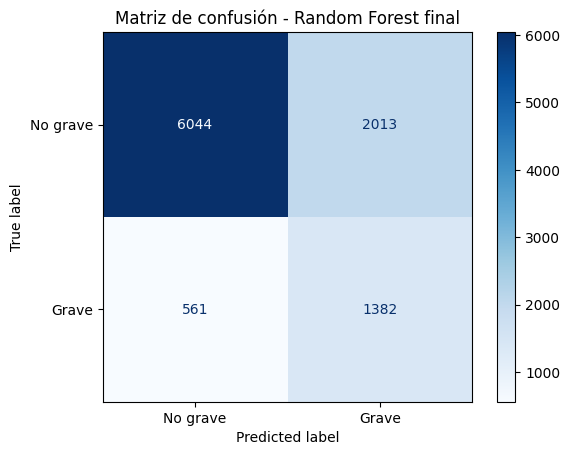

Resultados guardados correctamente.


In [ ]:

# Evaluación del Random Forest final

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Realizar predicciones

y_pred_rf_final = modelo_rf_final.predict(X_test_original)

y_prob_rf_final = modelo_rf_final.predict_proba(
    X_test_original
)[:, 1]

# Calcular métricas

metricas_rf_final = {
    "Accuracy": accuracy_score(y_test_original, y_pred_rf_final),
    "Precision": precision_score(y_test_original, y_pred_rf_final),
    "Recall": recall_score(y_test_original, y_pred_rf_final),
    "F1-Score": f1_score(y_test_original, y_pred_rf_final),
    "ROC-AUC": roc_auc_score(y_test_original, y_prob_rf_final)
}

tabla_rf_final = pd.DataFrame({
    "Métrica": list(metricas_rf_final.keys()),
    "Resultado": list(metricas_rf_final.values())
})

print("Resultados del Random Forest final:")
display(tabla_rf_final.round(4))

# Matriz de confusión

matriz_rf_final = confusion_matrix(
    y_test_original,
    y_pred_rf_final
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_rf_final,
    display_labels=["No grave", "Grave"]
)

disp.plot(cmap="Blues")
plt.title("Matriz de confusión - Random Forest final")
plt.show()

# Guardar métricas y matriz

tabla_rf_final.to_csv(
    carpeta + "/metricas_random_forest_final.csv",
    index=False
)

pd.DataFrame(
    matriz_rf_final,
    index=["Real_No_Grave", "Real_Grave"],
    columns=["Pred_No_Grave", "Pred_Grave"]
).to_csv(
    carpeta + "/matriz_confusion_random_forest.csv"
)

print("Resultados guardados correctamente.")


In [ ]:

# Resumen final de resultados del proyecto

import pandas as pd

resumen_modelos = pd.DataFrame({
    "Modelo": [
        "Random Forest - Parcial I",
        "Regresión Logística - Parcial II",
        "Random Forest - Parcial II"
    ],
    "Accuracy": [
        0.7355,
        metricas_finales["Accuracy"],
        metricas_rf_final["Accuracy"]
    ],
    "Precision": [
        0.4015,
        metricas_finales["Precision"],
        metricas_rf_final["Precision"]
    ],
    "Recall": [
        0.7360,
        metricas_finales["Recall"],
        metricas_rf_final["Recall"]
    ],
    "F1": [
        0.5195,
        metricas_finales["F1-Score"],
        metricas_rf_final["F1-Score"]
    ],
    "ROC_AUC": [
        0.7923,
        metricas_finales["ROC-AUC"],
        metricas_rf_final["ROC-AUC"]
    ]
})

print("Comparación final de los modelos:")
display(resumen_modelos.round(4))

# Guardar el resumen

resumen_modelos.to_csv(
    carpeta + "/resumen_final_modelos.csv",
    index=False
)

print("Resumen guardado correctamente.")


Comparación final de los modelos:


,Modelo,Accuracy,Precision,Recall,F1,ROC_AUC
0,Random Forest - Parcial I,0.7355,0.4015,0.7360,0.5195,0.7923
1,Regresión Logística - Parcial II,0.7096,0.3677,0.6876,0.4792,0.7717
2,Random Forest - Parcial II,0.7426,0.4071,0.7113,0.5178,0.7914


Resumen guardado correctamente.


In [ ]:

# Verificar respaldos del proyecto

import os
import pandas as pd

archivos_proyecto = []

for archivo in sorted(os.listdir(carpeta)):

    ruta = os.path.join(carpeta, archivo)

    if os.path.isfile(ruta):

        tamaño = os.path.getsize(ruta) / (1024 * 1024)

        archivos_proyecto.append({
            "Archivo": archivo,
            "Tamaño_MB": round(tamaño, 2),
            "Guardado": True
        })

tabla_archivos = pd.DataFrame(archivos_proyecto)

print("Archivos respaldados en Google Drive:")
display(tabla_archivos)

print("\nTotal de archivos:", len(tabla_archivos))

# Verificar archivos esenciales

archivos_esenciales = [
    "particion_parcial1.joblib",
    "datos_integracion_base.joblib",
    "noaa_agrupado.joblib",
    "fhwa_agrupado.joblib",
    "accidentes_integrados.joblib",
    "mejor_pipeline_logistico.joblib",
    "random_forest_final.joblib",
    "resumen_final_modelos.csv"
]

print("\nVerificación de archivos esenciales:")

for archivo in archivos_esenciales:
    existe = os.path.exists(os.path.join(carpeta, archivo))
    print(archivo, "-", "Correcto" if existe else "Faltante")

print("\nVerificación terminada.")


Archivos respaldados en Google Drive:


,Archivo,Tamaño_MB,Guardado
0,ablacion_imputacion.csv,0.00,True
1,ablacion_seleccion.csv,0.00,True
2,accidentes_integrados.joblib,8.90,True
3,comparacion_atipicos.csv,0.00,True
4,comparacion_metodos_seleccion.csv,0.00,True
5,comparacion_parcial1_parcial2.csv,0.00,True
6,datos_integracion_base.joblib,7.52,True
7,fhwa_agrupado.joblib,0.01,True
8,fhwa_original.joblib,0.31,True
9,matriz_confusion_random_forest.csv,0.00,True



Total de archivos: 28

Verificación de archivos esenciales:
particion_parcial1.joblib - Correcto
datos_integracion_base.joblib - Correcto
noaa_agrupado.joblib - Correcto
fhwa_agrupado.joblib - Correcto
accidentes_integrados.joblib - Correcto
mejor_pipeline_logistico.joblib - Correcto
random_forest_final.joblib - Correcto
resumen_final_modelos.csv - Correcto

Verificación terminada.


In [ ]:

# Verificación final del proyecto

import os
import joblib
import pandas as pd
import sklearn

# Cargar el modelo guardado

ruta_modelo = os.path.join(
    carpeta, "random_forest_final.joblib"
)

modelo_verificado = joblib.load(ruta_modelo)

# Comprobar que funciona

predicciones_verificacion = modelo_verificado.predict(
    X_test_original.head(10)
)

print("Modelo cargado correctamente.")
print("Predicciones de prueba:", predicciones_verificacion)

# Crear bitácora final

bitacora_final = pd.DataFrame({
    "Elemento": [
        "Proyecto",
        "Registros",
        "Entrenamiento",
        "Prueba",
        "Semilla",
        "Modelo final",
        "Imputación numérica",
        "Tratamiento de atípicos",
        "Selección de características",
        "Validación cruzada",
        "Versión de scikit-learn"
    ],
    "Configuración": [
        "Predicción de gravedad de accidentes",
        50000,
        40000,
        10000,
        42,
        "Random Forest",
        "Media",
        "Winsorización",
        "Sin selección",
        "Stratified K-Fold, 5 folds",
        sklearn.__version__
    ]
})

display(bitacora_final)

# Guardar bitácora

bitacora_final.to_csv(
    carpeta + "/bitacora_final.csv",
    index=False
)

print("Bitácora guardada correctamente.")


Modelo cargado correctamente.
Predicciones de prueba: [0 0 0 0 1 1 0 1 0 1]


,Elemento,Configuración
0,Proyecto,Predicción de gravedad de accidentes
1,Registros,50000
2,Entrenamiento,40000
3,Prueba,10000
4,Semilla,42
5,Modelo final,Random Forest
6,Imputación numérica,Media
7,Tratamiento de atípicos,Winsorización
8,Selección de características,Sin selección
9,Validación cruzada,"Stratified K-Fold, 5 folds"


Bitácora guardada correctamente.


In [ ]:

# Verificar ausencia de variables externas en el modelo

import pandas as pd
import os

variables_modelo = list(modelo_verificado.feature_names_in_)

variables_externas = [
    "Cantidad_Eventos_NOAA",
    "Tipos_Eventos_NOAA",
    "VMT_Total",
    "Integracion_NOAA",
    "Integracion_FHWA"
]

externas_utilizadas = [
    variable for variable in variables_externas
    if variable in variables_modelo
]

print("Variables originales del modelo:", len(variables_modelo))
print("Variables externas utilizadas:", externas_utilizadas)

print("\nPartición original:")
print("Entrenamiento:", len(X_train_original))
print("Prueba:", len(X_test_original))

assert len(variables_modelo) == 21
assert len(externas_utilizadas) == 0

# Guardar evidencia

verificacion = pd.DataFrame({
    "Comprobación": [
        "Variables predictoras originales",
        "Variables externas en el modelo",
        "Entrenamiento",
        "Prueba",
        "Fuga temporal por variables externas"
    ],
    "Resultado": [
        len(variables_modelo),
        len(externas_utilizadas),
        len(X_train_original),
        len(X_test_original),
        "No se incorporaron"
    ]
})

display(verificacion)

verificacion.to_csv(
    os.path.join(carpeta, "verificacion_variables_externas.csv"),
    index=False
)

print("Verificación guardada correctamente.")


Variables originales del modelo: 21
Variables externas utilizadas: []

Partición original:
Entrenamiento: 40000
Prueba: 10000


,Comprobación,Resultado
0,Variables predictoras originales,21
1,Variables externas en el modelo,0
2,Entrenamiento,40000
3,Prueba,10000
4,Fuga temporal por variables externas,No se incorporaron


Verificación guardada correctamente.
